# Corporate Default & Distress Prediction
Harpreet Singh Anand

Data: an anonymized panel of 8,262 firms (78,682 firm-years, fiscal 1999-2018) simulated to reproduce the structure of a corporate-bankruptcy prediction problem. It is not included in this repo (see README).

Split used throughout: train = fiscal 1999-2011, validation = 2012-2014, test = 2015-2018. The test sample is only used once, in Section 5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA = "data/"  # not included in this repo, see README
df = pd.read_csv(DATA + "model_data_1999_2018.csv")
raw = pd.read_csv(DATA + "raw_firm_year_1999_2018.csv")
counts = pd.read_csv(DATA + "annual_counts.csv")
dictionary = pd.read_csv(DATA + "data_dictionary.csv")
print("model data:", df.shape, " raw:", raw.shape, " counts:", counts.shape, " dictionary:", dictionary.shape)
df.head()

model data: (78682, 27)  raw: (78682, 27)  counts: (20, 4)  dictionary: (54, 5)


## 1. Data audit, rare events and EDA
### 1.1 Sample checks

In [2]:
print("fiscal years:", df.fiscal_year.min(), "-", df.fiscal_year.max())
print("target years:", df.target_year.min(), "-", df.target_year.max())
print("observations:", len(df))
print("firms:", df.company_id.nunique())
print("total defaults:", df.y_default.sum())
print("target_year == fiscal_year + 1 for all rows:", (df.target_year == df.fiscal_year + 1).all())
print("duplicate firm-years:", df.duplicated(["company_id", "fiscal_year"]).sum())
print("y_default values:", sorted(df.y_default.unique()))

# split column should match the fiscal-year rule exactly
rule = np.where(df.fiscal_year <= 2011, "train", np.where(df.fiscal_year <= 2014, "validation", "test"))
print("split values:", df.split.unique())
print("rows where split column disagrees with year rule:", (df.split != rule).sum())

fiscal years: 1999 - 2018
target years: 2000 - 2019
observations: 78682
firms: 8262
total defaults: 609
target_year == fiscal_year + 1 for all rows: True
duplicate firm-years: 0
y_default values: [0, 1]
split values: ['train' 'validation' 'test']
rows where split column disagrees with year rule: 0


In [3]:
split_order = ["train", "validation", "test"]
split_tab = df.groupby("split").agg(fiscal_from=("fiscal_year", "min"), fiscal_to=("fiscal_year", "max"),
                                    obs=("y_default", "size"), firms=("company_id", "nunique"),
                                    defaults=("y_default", "sum"), default_rate=("y_default", "mean")).loc[split_order]
split_tab.loc["total"] = [df.fiscal_year.min(), df.fiscal_year.max(), len(df), df.company_id.nunique(),
                          df.y_default.sum(), df.y_default.mean()]
split_tab["default_rate_%"] = 100 * split_tab["default_rate"]
split_tab = split_tab.drop(columns="default_rate")
split_tab[["fiscal_from", "fiscal_to", "obs", "firms", "defaults"]] = split_tab[["fiscal_from", "fiscal_to", "obs", "firms", "defaults"]].astype(int)
split_tab.round(3)

,fiscal_from,fiscal_to,obs,firms,defaults,default_rate_%
split,,,,,,
train,1999,2011,55927,8262,403,0.7210
validation,2012,2014,10473,4169,87,0.8310
test,2015,2018,12282,3712,119,0.9690
total,1999,2018,78682,8262,609,0.7740


In [4]:
# missing and infinite values
num_cols = df.select_dtypes("number").columns
miss = pd.DataFrame({"missing": df.isna().sum(), "infinite": np.isinf(df[num_cols]).sum().reindex(df.columns).fillna(0).astype(int)})
print("total missing:", miss.missing.sum(), " total infinite:", miss.infinite.sum())
miss[(miss.missing > 0) | (miss.infinite > 0)]

total missing: 0  total infinite: 0


,missing,infinite


In [5]:
# the raw firm-year file should line up row for row with the model file
key = ["company_id", "fiscal_year", "target_year", "industry_code", "split", "y_default"]
m = df[key].merge(raw[key], on=["company_id", "fiscal_year"], how="outer", suffixes=("", "_raw"), indicator=True)
print(m["_merge"].value_counts())
for c in ["target_year", "industry_code", "split", "y_default"]:
    print(c, "mismatches:", (m[c] != m[c + "_raw"]).sum())

# spot check two ratios rebuilt from raw values
r = df.merge(raw, on=["company_id", "fiscal_year"], suffixes=("", "_raw"))
print("max |current_ratio - CA/CL|:", (r.current_ratio - r.current_assets / r.current_liabilities).abs().max())
print("max |debt_to_assets - TL/TA|:", (r.debt_to_assets - r.total_liabilities / r.total_assets).abs().max())

_merge
both          78682
left_only         0
right_only        0
Name: count, dtype: int64
target_year mismatches: 0
industry_code mismatches: 0
split mismatches: 0
y_default mismatches: 0
max |current_ratio - CA/CL|: 5.216375091876557e-07
max |debt_to_assets - TL/TA|: 5.001327655351773e-07


In [6]:
# cross-check annual counts (by target_year) against the provided file
ann = df.groupby("target_year").agg(obs=("y_default", "size"), defaults=("y_default", "sum"), rate=("y_default", "mean"))
chk = ann.join(counts.set_index("target_year").add_suffix("_file"))
chk["obs_diff"] = chk.obs - chk.firm_year_observations_file
chk["def_diff"] = chk.defaults - chk.defaults_file
chk["rate_diff"] = chk.rate - chk.default_rate_file
print("max abs differences  obs:", chk.obs_diff.abs().max(), " defaults:", chk.def_diff.abs().max(),
      " rate:", chk.rate_diff.abs().max())
chk

max abs differences  obs: 0  defaults: 0  rate: 9.71445146547012e-17


,obs,defaults,rate,firm_year_observations_file,defaults_file,default_rate_file,obs_diff,def_diff,rate_diff
target_year,,,,,,,,,
2000,5308,3,0.0006,5308,3,0.0006,0,0,0.0000
2001,5226,7,0.0013,5226,7,0.0013,0,0,0.0000
2002,4897,10,0.0020,4897,10,0.0020,0,0,0.0000
2003,4651,17,0.0037,4651,17,0.0037,0,0,0.0000
2004,4417,29,0.0066,4417,29,0.0066,0,0,0.0000
2005,4348,46,0.0106,4348,46,0.0106,0,0,0.0000
2006,4205,40,0.0095,4205,40,0.0095,0,0,0.0000
2007,4128,51,0.0124,4128,51,0.0124,0,0,0.0000
2008,4009,59,0.0147,4009,59,0.0147,0,0,0.0000


Everything matches: 78,682 firm-years, 8,262 firms, 609 defaults, no missing or infinite values, and the annual counts agree exactly with `annual_counts.csv`.

### 1.2 Annual default rate

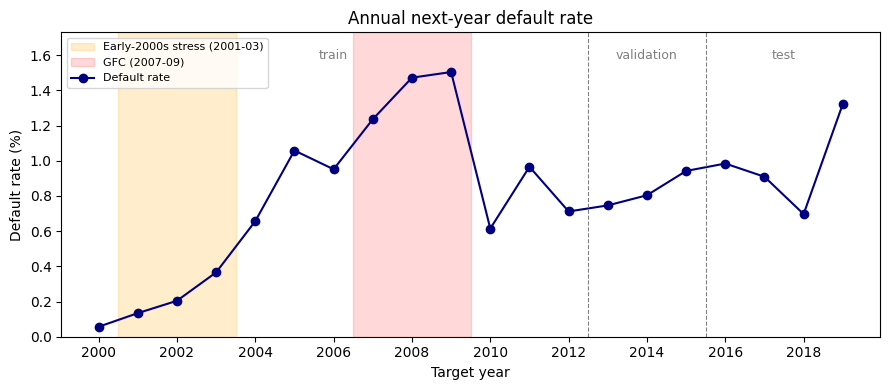

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(2000.5, 2003.5, color="orange", alpha=0.2, label="Early-2000s stress (2001-03)")
ax.axvspan(2006.5, 2009.5, color="red", alpha=0.15, label="GFC (2007-09)")
ax.plot(ann.index, 100 * ann.rate, marker="o", color="navy", label="Default rate")
for s, (a, b) in {"train": (2000, 2012), "validation": (2013, 2015), "test": (2016, 2019)}.items():
    ax.text((a + b) / 2, 100 * ann.rate.max() * 1.05, s, ha="center", fontsize=9, color="gray")
for x in [2012.5, 2015.5]:
    ax.axvline(x, color="gray", ls="--", lw=0.8)
ax.set_xlabel("Target year")
ax.set_ylabel("Default rate (%)")
ax.set_title("Annual next-year default rate")
ax.set_xticks(range(2000, 2020, 2))
ax.set_ylim(0, 100 * ann.rate.max() * 1.15)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("figures/annual_default_rate.png", dpi=200)
plt.show()

The GFC years (2007-09) are the clear peak (about 1.2-1.5%). In this teaching sample the early-2000s window is not a spike: rates are low (0.1-0.4%) but rising quickly, so that period looks more like the build-up of distress. 2019 is also high, which matters for the test period.

### 1.3 Rare events
- Defaults are well under 1% of firm-years, so a model that predicts "no default" for everyone is >99% accurate and useless. Accuracy is dominated by the majority class, so I use ranking metrics (ROC-AUC, PR-AUC, KS) and default capture instead.
- A random split would put firms from the same year (and the same firm in adjacent years) in both train and test, which leaks future information and common shocks. The chronological split mimics real use: fit on the past and predict later years.

In [8]:
naive_acc = 1 - df.groupby("split").y_default.mean().loc[split_order]
print("accuracy of always predicting 'no default':")
print((100 * naive_acc).round(3).astype(str) + "%")

accuracy of always predicting 'no default':
split
train         99.279%
validation    99.169%
test          99.031%
Name: y_default, dtype: object


### Exact identities in the ratios
Two pairs look like they are exact complements. If so, plain logistic regression cannot separate them.

In [9]:
print("max |debt_to_assets + equity_to_assets - 1|:", (df.debt_to_assets + df.equity_to_assets - 1).abs().max())
print("max |gross_margin + cogs_to_sales - 1|:", (df.gross_margin + df.cogs_to_sales - 1).abs().max())
print("corr(ebit_to_assets, ebitda_to_assets):", df[["ebit_to_assets", "ebitda_to_assets"]].corr().iloc[0, 1].round(4))

max |debt_to_assets + equity_to_assets - 1|: 0.0
max |gross_margin + cogs_to_sales - 1|: 0.0
corr(ebit_to_assets, ebitda_to_assets): 0.9852


### 1.4 Predictor groups and chronological split

In [10]:
groups = {
    "Liquidity": ["current_ratio", "quick_ratio"],
    "Leverage": ["debt_to_assets", "longterm_debt_to_assets", "current_liabilities_to_assets", "equity_to_assets"],
    "Profitability": ["net_income_to_assets", "ebitda_to_assets", "ebit_to_assets", "retained_earnings_to_assets", "gross_margin"],
    "Efficiency": ["sales_to_assets", "cogs_to_sales", "operating_expense_to_sales", "receivables_to_sales", "inventory_to_sales"],
    "Market": ["market_to_book", "log_market_value", "annual_return", "return_volatility", "market_beta"],
}
cont_cols = [c for g in groups.values() for c in g]
cat_cols = ["industry_code"]
# exact identities found above, so these two are dropped from the linear models only
linear_drop = ["equity_to_assets", "cogs_to_sales"]
cont_linear = [c for c in cont_cols if c not in linear_drop]
target = "y_default"

train = df[df["fiscal_year"] <= 2011].copy()
valid = df[df["fiscal_year"].between(2012, 2014)].copy()
test = df[df["fiscal_year"] >= 2015].copy()
print("continuous predictors:", len(cont_cols), "| used in linear models:", len(cont_linear))
print("train / valid / test:", len(train), len(valid), len(test))
print("columns not in any group:", [c for c in df.columns if c not in cont_cols + cat_cols + ["company_id", "fiscal_year", "target_year", "split", target]])

continuous predictors: 21 | used in linear models: 19
train / valid / test: 55927 10473 12282
columns not in any group: []


### 1.5 Training-sample descriptive statistics

In [11]:
desc = train[cont_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["skew"] = train[cont_cols].skew()
desc.insert(0, "group", [g for g, cols in groups.items() for c in cols])
desc.drop(columns="count").round(3)

,group,mean,std,min,1%,25%,50%,75%,99%,max,skew
current_ratio,Liquidity,0.9270,0.3840,0.1970,0.3510,0.6490,0.8480,1.1220,2.0830,4.0000,1.1750
quick_ratio,Liquidity,0.7320,0.3070,0.1520,0.2740,0.5090,0.6690,0.8860,1.6890,3.1510,1.1850
debt_to_assets,Leverage,0.4110,0.1890,0.0300,0.0440,0.2650,0.4010,0.5500,0.8290,0.9700,0.1760
longterm_debt_to_assets,Leverage,0.2010,0.0970,0.0110,0.0210,0.1270,0.1940,0.2680,0.4380,0.5740,0.3530
current_liabilities_to_assets,Leverage,0.1480,0.0700,0.0240,0.0300,0.0940,0.1430,0.1970,0.3170,0.4230,0.3500
equity_to_assets,Leverage,0.5890,0.1890,0.0300,0.1710,0.4500,0.5990,0.7350,0.9560,0.9700,-0.1760
net_income_to_assets,Profitability,0.0670,0.0580,-0.1950,-0.0800,0.0300,0.0680,0.1060,0.1960,0.2850,-0.2120
ebitda_to_assets,Profitability,0.1320,0.0690,-0.1570,-0.0300,0.0860,0.1330,0.1790,0.2900,0.4020,-0.0540
ebit_to_assets,Profitability,0.0970,0.0700,-0.1870,-0.0670,0.0500,0.0980,0.1450,0.2570,0.3820,-0.0550
retained_earnings_to_assets,Profitability,0.1400,0.1380,-0.4520,-0.1790,0.0470,0.1410,0.2340,0.4590,0.6860,-0.0120


The course data already looks bounded (e.g. debt_to_assets between 0.03 and 0.97, current_ratio at most 4), but receivables_to_sales, inventory_to_sales and market_to_book are still right-skewed. I winsorize all ratios at the training 1st/99th percentiles before the linear models as a safety step.

In [12]:
# default vs non-default (training only)
comp_vars = ["current_ratio", "debt_to_assets", "longterm_debt_to_assets", "net_income_to_assets",
             "retained_earnings_to_assets", "ebitda_to_assets", "sales_to_assets",
             "market_to_book", "log_market_value", "annual_return", "return_volatility", "market_beta"]
g = train.groupby(target)[comp_vars]
comp = pd.concat({"mean_nondefault": g.mean().loc[0], "mean_default": g.mean().loc[1],
                  "median_nondefault": g.median().loc[0], "median_default": g.median().loc[1]}, axis=1)
comp["median_diff"] = comp.median_default - comp.median_nondefault
comp.round(3)

,mean_nondefault,mean_default,median_nondefault,median_default,median_diff
current_ratio,0.9270,0.8380,0.8490,0.7740,-0.0750
debt_to_assets,0.4100,0.5270,0.4000,0.5370,0.1370
longterm_debt_to_assets,0.2010,0.2600,0.1940,0.2600,0.0660
net_income_to_assets,0.0670,0.0490,0.0680,0.0480,-0.0200
retained_earnings_to_assets,0.1410,0.0780,0.1410,0.0810,-0.0610
ebitda_to_assets,0.1320,0.1130,0.1330,0.1120,-0.0210
sales_to_assets,1.0050,1.0090,0.9560,0.9680,0.0110
market_to_book,1.6600,1.5450,1.5440,1.4490,-0.0950
log_market_value,9.2660,8.8760,9.2720,8.9570,-0.3150
annual_return,-0.0850,-0.2230,-0.0640,-0.1760,-0.1120


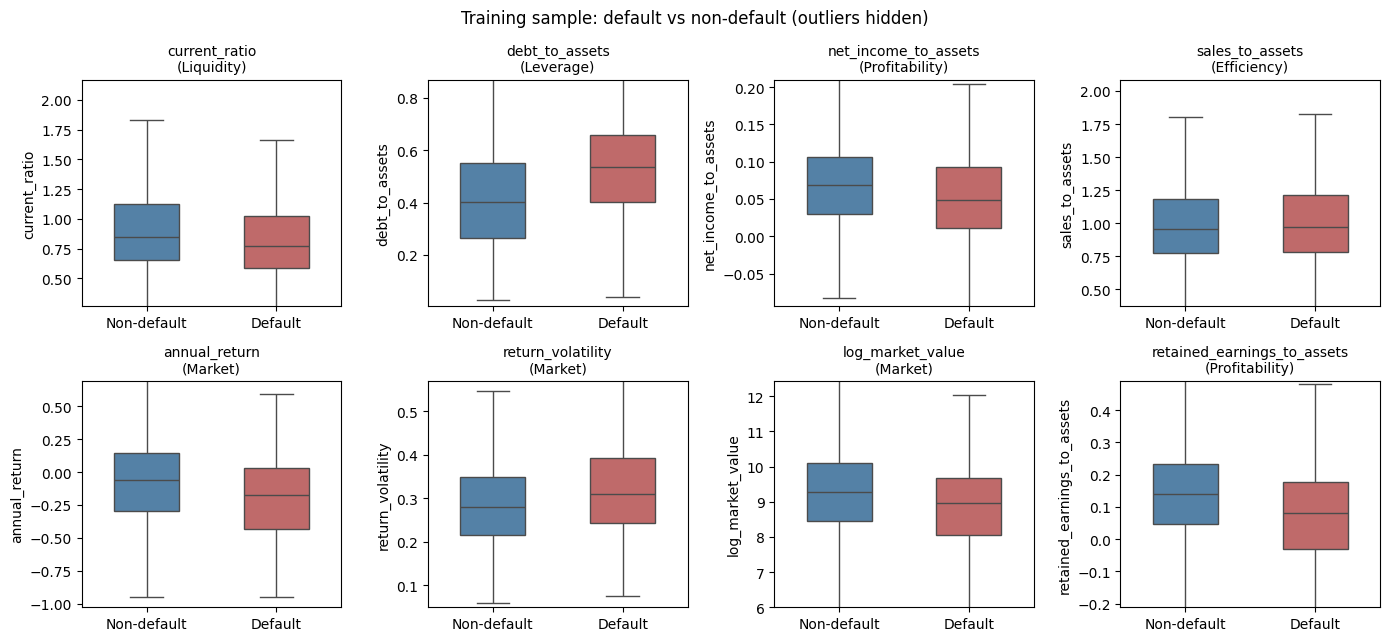

In [13]:
# distribution plots for one variable from each group; y-axis cut at the training 1st/99th pct so the boxes are readable
plot_vars = [("current_ratio", "Liquidity"), ("debt_to_assets", "Leverage"), ("net_income_to_assets", "Profitability"),
             ("sales_to_assets", "Efficiency"), ("annual_return", "Market"), ("return_volatility", "Market"),
             ("log_market_value", "Market"), ("retained_earnings_to_assets", "Profitability")]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, (v, grp) in zip(axes.ravel(), plot_vars):
    lo, hi = train[v].quantile([0.01, 0.99])
    sns.boxplot(data=train, x=target, y=v, ax=ax, showfliers=False, palette=["steelblue", "indianred"], width=0.5)
    ax.set_ylim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
    ax.set_xticklabels(["Non-default", "Default"])
    ax.set_xlabel("")
    ax.set_title(f"{v}\n({grp})", fontsize=10)
plt.suptitle("Training sample: default vs non-default (outliers hidden)")
plt.tight_layout()
plt.savefig("figures/eda_boxplots.png", dpi=200)
plt.show()

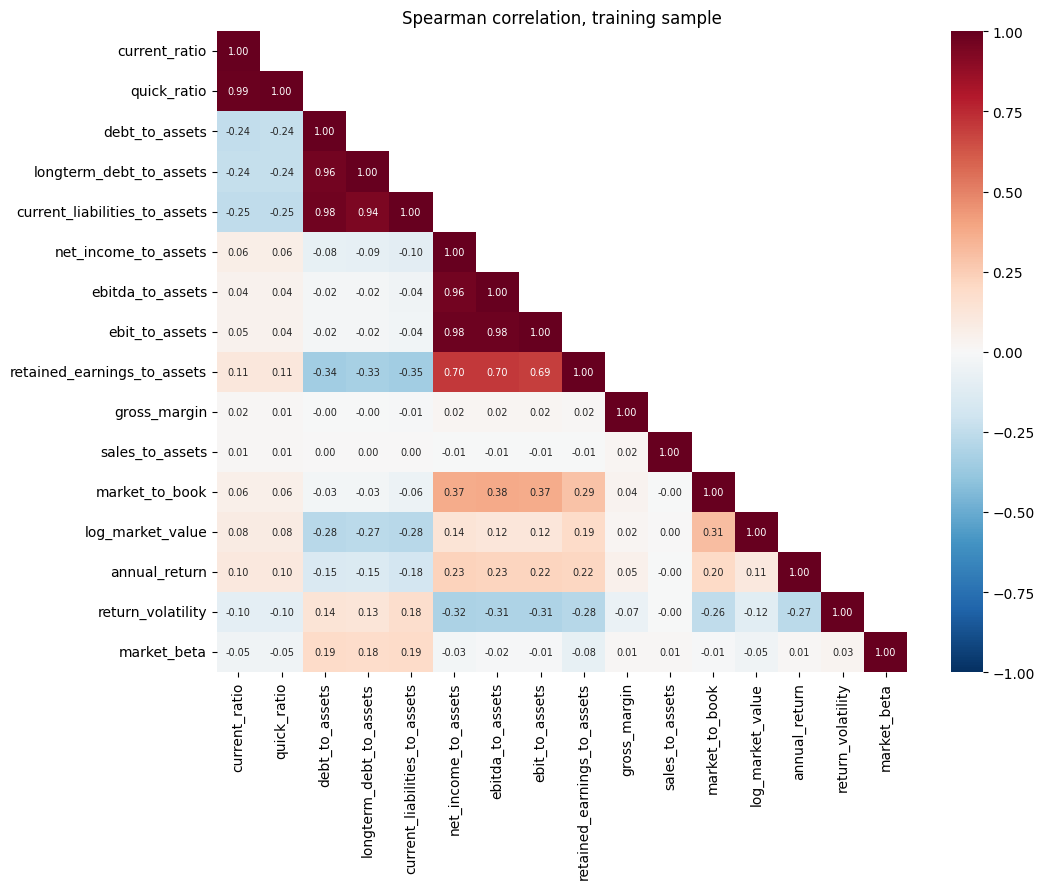

In [14]:
# Spearman correlation because the ratios are heavy tailed
heat_vars = ["current_ratio", "quick_ratio", "debt_to_assets", "longterm_debt_to_assets", "current_liabilities_to_assets",
             "net_income_to_assets", "ebitda_to_assets", "ebit_to_assets", "retained_earnings_to_assets", "gross_margin",
             "sales_to_assets", "market_to_book", "log_market_value", "annual_return", "return_volatility", "market_beta"]
corr = train[heat_vars].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7},
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax)
ax.set_title("Spearman correlation, training sample")
plt.tight_layout()
plt.savefig("figures/corr_heatmap.png", dpi=200)
plt.show()

In [15]:
# strongest pairs
pairs = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack().rename("rho").reset_index()
pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(10).round(3)

,level_0,level_1,rho
0,current_ratio,quick_ratio,0.9860
75,ebitda_to_assets,ebit_to_assets,0.9840
66,net_income_to_assets,ebit_to_assets,0.9800
30,debt_to_assets,current_liabilities_to_assets,0.9750
65,net_income_to_assets,ebitda_to_assets,0.9640
29,debt_to_assets,longterm_debt_to_assets,0.9630
42,longterm_debt_to_assets,current_liabilities_to_assets,0.9410
76,ebitda_to_assets,retained_earnings_to_assets,0.7040
67,net_income_to_assets,retained_earnings_to_assets,0.7030
84,ebit_to_assets,retained_earnings_to_assets,0.6930


In [16]:
# correlation of each predictor with the default flag (Spearman)
train[cont_cols].corrwith(train[target], method="spearman").sort_values().round(3)

equity_to_assets                -0.0510
retained_earnings_to_assets     -0.0370
annual_return                   -0.0310
net_income_to_assets            -0.0250
log_market_value                -0.0250
ebitda_to_assets                -0.0230
ebit_to_assets                  -0.0220
current_ratio                   -0.0200
quick_ratio                     -0.0200
market_to_book                  -0.0130
gross_margin                    -0.0040
market_beta                      0.0000
sales_to_assets                  0.0030
cogs_to_sales                    0.0040
operating_expense_to_sales       0.0220
return_volatility                0.0250
receivables_to_sales             0.0270
inventory_to_sales               0.0280
longterm_debt_to_assets          0.0510
debt_to_assets                   0.0510
current_liabilities_to_assets    0.0520
dtype: float64

Correlation patterns (training sample):
- Leverage is basically one factor: debt_to_assets, long-term debt and current liabilities to assets have rho 0.94-0.98.
- Profitability is also one factor: net income, EBIT and EBITDA to assets have rho 0.96-0.98, and retained earnings is linked to them (about 0.70).
- current_ratio and quick_ratio are almost identical (0.99), and liquidity is mildly negative with leverage (-0.24).
- Riskier firms cluster: volatility is negative with profitability (-0.31), M/B (-0.26) and returns (-0.27); larger firms have lower leverage (-0.28).
- gross_margin, sales_to_assets and market_beta are nearly uncorrelated with everything else.
- Each single predictor is only weakly related to the default flag (|rho| at most about 0.05), as expected with 0.7% defaults.

The strong within-group correlations mean linear coefficients inside a group will be unstable, which is one reason to look at LASSO and Ridge.

### 1.6 Expected direction of default risk
| Variable | Expected sign | Reason |
|---|---|---|
| debt_to_assets, longterm_debt_to_assets | + | more debt means less equity cushion before assets fall below liabilities |
| current_ratio, quick_ratio | - | more liquid assets to cover short-term obligations |
| net_income / ebitda / ebit to assets | - | profitable firms generate cash to service debt |
| retained_earnings_to_assets | - | accumulated past profits; young or loss-making firms have low or negative RE |
| annual_return | - | the market prices bad news early, so weak returns signal distress |
| return_volatility | + | higher asset volatility raises the probability of hitting the default boundary (Merton) |
| log_market_value | - | larger firms are more diversified and have better access to capital |
| market_to_book | - (weak) | low M/B means the market values equity close to or below book |

The default-vs-non-default medians above agree with these signs. sales_to_assets and market_beta show almost no difference, so I do not expect them to matter much.

## 2. Linear benchmark models
Preprocessing is fit on the training sample only: winsorize at the training 1st/99th percentiles, standardize, and one-hot encode industry_code (first level dropped so the plain logit is identified). C is chosen by validation PR-AUC, because with <1% defaults PR-AUC is the metric most focused on the defaulters; ROC-AUC and KS are reported as well.

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, brier_score_loss, accuracy_score)


class Winsorizer(BaseEstimator, TransformerMixin):
    # caps learned on the data passed to fit (training sample only)
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.quantile(X, self.lower, axis=0)
        self.hi_ = np.quantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)


def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()


def top_decile_capture(y, p):
    # share of all defaults that fall in the 10% highest predicted probabilities
    y = np.asarray(y)
    n_top = int(np.ceil(0.10 * len(y)))
    idx = np.argsort(-np.asarray(p), kind="mergesort")[:n_top]
    return y[idx].sum() / y.sum()


def rank_metrics(y, p):
    return {"ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "KS": ks_stat(y, p), "Top10_capture": top_decile_capture(y, p)}


def make_linear_prep():
    return ColumnTransformer([
        ("num", Pipeline([("winsor", Winsorizer()), ("scale", StandardScaler())]), cont_linear),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)])


X_train, y_train = train[cont_cols + cat_cols], train[target].values
X_valid, y_valid = valid[cont_cols + cat_cols], valid[target].values
X_test, y_test = test[cont_cols + cat_cols], test[target].values
print("base rate train / valid:", y_train.mean().round(4), y_valid.mean().round(4))

base rate train / valid: 0.0072 0.0083


In [18]:
C_grid = [0.01, 0.1, 1, 10]
lin_specs = {"Logit": [dict(penalty=None, solver="lbfgs")]}
lin_specs["LASSO"] = [dict(penalty="l1", solver="saga", C=c) for c in C_grid]
lin_specs["Ridge"] = [dict(penalty="l2", solver="lbfgs", C=c) for c in C_grid]

rows, fitted = [], {}
for name, specs in lin_specs.items():
    for params in specs:
        pipe = Pipeline([("prep", make_linear_prep()),
                         ("clf", LogisticRegression(max_iter=5000, random_state=SEED, **params))])
        pipe.fit(X_train, y_train)
        p = pipe.predict_proba(X_valid)[:, 1]
        r = {"model": name, "C": params.get("C", np.nan)}
        r.update(rank_metrics(y_valid, p))
        r["nonzero_coefs"] = int((np.abs(pipe.named_steps["clf"].coef_) > 1e-6).sum())
        rows.append(r)
        fitted[(name, params.get("C"))] = pipe
lin_grid = pd.DataFrame(rows)
lin_grid.round(4)

,model,C,ROC_AUC,PR_AUC,KS,Top10_capture,nonzero_coefs
0,Logit,NaN,0.6775,0.0220,0.2825,0.2989,28
1,LASSO,0.0100,0.6704,0.0247,0.2477,0.2874,5
2,LASSO,0.1000,0.6939,0.0265,0.3022,0.3218,11
3,LASSO,1.0000,0.6887,0.0255,0.3016,0.3103,23
4,LASSO,10.0000,0.6885,0.0255,0.3038,0.2989,27
5,Ridge,0.0100,0.6938,0.0267,0.3076,0.2989,28
6,Ridge,0.1000,0.6905,0.0257,0.2940,0.3103,28
7,Ridge,1.0000,0.6781,0.0223,0.2865,0.2989,28
8,Ridge,10.0000,0.6776,0.0220,0.2822,0.2989,28


In [19]:
# choose C by validation PR-AUC
best_C = {}
for name in ["LASSO", "Ridge"]:
    sub = lin_grid[lin_grid.model == name]
    best_C[name] = sub.loc[sub.PR_AUC.idxmax(), "C"]
print("selected C:", best_C)

final_models = {"M1 Logit": fitted[("Logit", None)],
                "M2 LASSO": fitted[("LASSO", best_C["LASSO"])],
                "M3 Ridge": fitted[("Ridge", best_C["Ridge"])]}
val_pred = {k: m.predict_proba(X_valid)[:, 1] for k, m in final_models.items()}
lin_val = pd.DataFrame({k: rank_metrics(y_valid, p) for k, p in val_pred.items()}).T
lin_val["C"] = [np.nan, best_C["LASSO"], best_C["Ridge"]]
lin_val[["C", "ROC_AUC", "PR_AUC", "KS", "Top10_capture"]].round(4)

selected C: {'LASSO': 0.1, 'Ridge': 0.01}


,C,ROC_AUC,PR_AUC,KS,Top10_capture
M1 Logit,NaN,0.6775,0.0220,0.2825,0.2989
M2 LASSO,0.1000,0.6939,0.0265,0.3022,0.3218
M3 Ridge,0.0100,0.6938,0.0267,0.3076,0.2989


In [20]:
# standardized coefficients of the three selected linear models
feat_names = [n.split("__")[1] for n in final_models["M1 Logit"].named_steps["prep"].get_feature_names_out()]
coefs = pd.DataFrame({k: m.named_steps["clf"].coef_.ravel() for k, m in final_models.items()}, index=feat_names)
lasso_zero = coefs.index[np.abs(coefs["M2 LASSO"]) < 1e-6].tolist()
print(f"LASSO (C={best_C['LASSO']}): {len(lasso_zero)} of {len(coefs)} coefficients set to zero")
print("zeroed:", lasso_zero)
coefs.round(3).sort_values("M1 Logit", key=np.abs, ascending=False)

LASSO (C=0.1): 17 of 28 coefficients set to zero
zeroed: ['current_ratio', 'current_liabilities_to_assets', 'net_income_to_assets', 'ebit_to_assets', 'gross_margin', 'sales_to_assets', 'receivables_to_sales', 'inventory_to_sales', 'market_to_book', 'industry_code_2', 'industry_code_3', 'industry_code_5', 'industry_code_6', 'industry_code_7', 'industry_code_8', 'industry_code_9', 'industry_code_10']


,M1 Logit,M2 LASSO,M3 Ridge
industry_code_5,-0.6470,0.0000,-0.0770
industry_code_6,-0.5600,0.0000,-0.0570
industry_code_3,-0.5120,0.0000,-0.0450
industry_code_10,-0.4420,0.0000,-0.0250
industry_code_9,-0.3380,0.0000,0.0010
industry_code_7,-0.3110,0.0000,0.0050
debt_to_assets,0.2750,0.3080,0.1730
annual_return,-0.2150,-0.2120,-0.1870
longterm_debt_to_assets,0.2150,0.1730,0.1780
industry_code_2,-0.2090,0.0000,0.0370


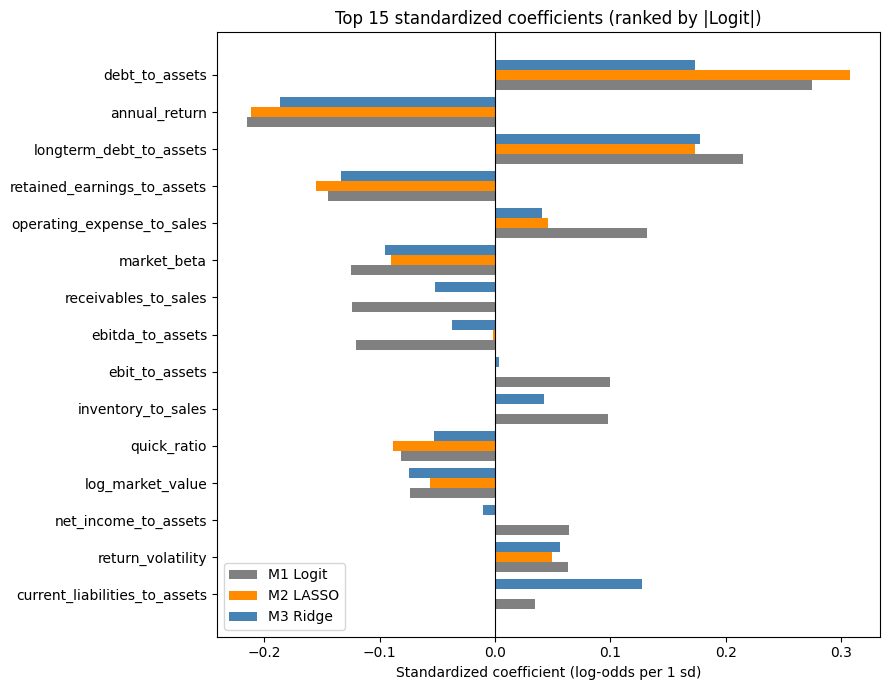

In [21]:
# only the standardized continuous predictors; industry dummies are 0/1 and not on a per-sd scale
num_coefs = coefs.loc[cont_linear]
top = num_coefs["M1 Logit"].abs().sort_values(ascending=False).index[:15][::-1]
fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(top))
h = 0.27
for i, (k, col) in enumerate(zip(coefs.columns, ["gray", "darkorange", "steelblue"])):
    ax.barh(yy + (i - 1) * h, coefs.loc[top, k], height=h, color=col, label=k)
ax.set_yticks(yy)
ax.set_yticklabels(top)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Standardized coefficient (log-odds per 1 sd)")
ax.set_title("Top 15 standardized coefficients (ranked by |Logit|)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/linear_coefs.png", dpi=200)
plt.show()

In [22]:
# sign check against the expected directions from 1.6
expected = {"debt_to_assets": "+", "longterm_debt_to_assets": "+", "current_ratio": "-", "net_income_to_assets": "-",
            "retained_earnings_to_assets": "-", "annual_return": "-", "return_volatility": "+",
            "log_market_value": "-", "market_to_book": "-"}
sign_tab = coefs.loc[list(expected)].copy()
sign_tab.insert(0, "expected", pd.Series(expected))
for k in ["M1 Logit", "M2 LASSO", "M3 Ridge"]:
    sign_tab[k + " sign"] = np.where(sign_tab[k].abs() < 1e-6, "0", np.where(sign_tab[k] > 0, "+", "-"))
sign_tab.round(3)

,expected,M1 Logit,M2 LASSO,M3 Ridge,M1 Logit sign,M2 LASSO sign,M3 Ridge sign
debt_to_assets,+,0.2750,0.3080,0.1730,+,+,+
longterm_debt_to_assets,+,0.2150,0.1730,0.1780,+,+,+
current_ratio,-,-0.0060,0.0000,-0.0370,-,0,-
net_income_to_assets,-,0.0650,0.0000,-0.0100,+,0,-
retained_earnings_to_assets,-,-0.1450,-0.1550,-0.1340,-,-,-
annual_return,-,-0.2150,-0.2120,-0.1870,-,-,-
return_volatility,+,0.0630,0.0500,0.0560,+,+,+
log_market_value,-,-0.0730,-0.0560,-0.0740,-,-,-
market_to_book,-,0.0180,0.0000,0.0150,+,0,+


Notes on the linear models (coefficients are associations, not causal effects):
- Regularization helps a little on validation: plain logit PR-AUC 0.022 vs about 0.027 for LASSO (C=0.1) and Ridge (C=0.01). Ridge picks the smallest C in the grid, so it wants strong shrinkage.
- LASSO keeps 11 of 28 coefficients. It drops all industry dummies except one, and keeps one member of each correlated block (debt_to_assets + long-term debt for leverage, retained earnings for profitability, quick_ratio for liquidity).
- Signs that match theory in all three models: leverage (+), long-term debt (+), retained earnings (-), annual return (-), volatility (+), firm size (-).
- Unstable signs: net_income_to_assets is + in the plain logit and EBIT is +, while EBITDA is -. This is the profitability block splitting one effect across three near-identical ratios. Ridge pulls them back toward small negative values and LASSO keeps only retained earnings.
- The industry dummies in the plain logit are large (relative to industry 1), but LASSO and Ridge shrink them close to zero, so the industry effect is weak once we penalize.
- The same variables lead after regularization: debt_to_assets, annual_return, long-term debt and retained earnings are the top four for all three models.
- Ridge spreads the leverage effect across the leverage block (current_liabilities_to_assets goes from 0.03 to 0.13), while LASSO picks one ratio. market_beta comes out negative in all three, which is the opposite of a simple risk story, but its effect is small.

## 3. Trees, bagging and boosting
Trees use all 21 ratios (no scaling or winsorizing needed, since splits only depend on the order of values) plus one-hot industry. Selection is again by validation PR-AUC.

In [23]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import time


def make_tree_prep():
    return ColumnTransformer([("num", "passthrough", cont_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])


def tree_pipe(clf):
    return Pipeline([("prep", make_tree_prep()), ("clf", clf)])

### Decision tree: complexity curve

max_depth  train_ROC_AUC  valid_ROC_AUC  leaves
        1         0.6437         0.6108       2
        2         0.6457         0.6108       4
        3         0.6479         0.6107       6
        4         0.6678         0.6174      10
        5         0.6964         0.6217      14
        6         0.7063         0.6257      21
        7         0.7155         0.6218      30
        8         0.7379         0.6380      41
        9         0.7505         0.6356      56
       10         0.7686         0.6135      78
       11         0.7973         0.6155     108
       12         0.8193         0.5902     140
       13         0.8464         0.5855     175
       14         0.8717         0.5821     219
       15         0.8960         0.5654     266
     None         1.0000         0.5024     726


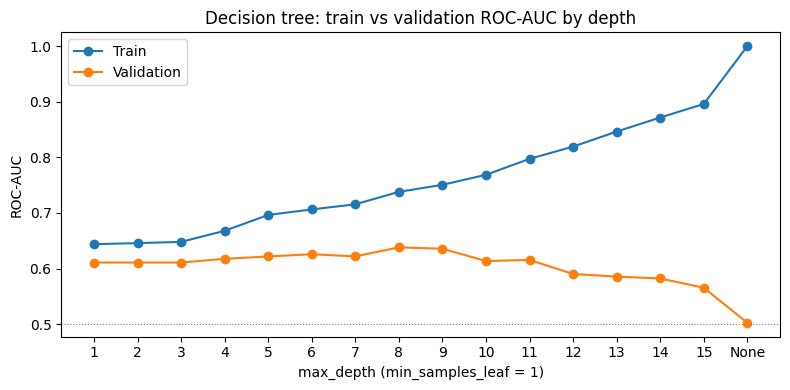

In [24]:
depths = list(range(1, 16)) + [None]
rows = []
for d in depths:
    m = tree_pipe(DecisionTreeClassifier(max_depth=d, random_state=SEED)).fit(X_train, y_train)
    rows.append({"max_depth": "None" if d is None else d,
                 "train_ROC_AUC": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
                 "valid_ROC_AUC": roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]),
                 "leaves": m.named_steps["clf"].get_n_leaves()})
depth_curve = pd.DataFrame(rows)
print(depth_curve.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
xs = np.arange(len(depth_curve))
ax.plot(xs, depth_curve.train_ROC_AUC, marker="o", label="Train")
ax.plot(xs, depth_curve.valid_ROC_AUC, marker="o", label="Validation")
ax.set_xticks(xs)
ax.set_xticklabels(depth_curve.max_depth)
ax.set_xlabel("max_depth (min_samples_leaf = 1)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Decision tree: train vs validation ROC-AUC by depth")
ax.axhline(0.5, color="gray", ls=":", lw=0.8)
ax.legend()
plt.tight_layout()
plt.savefig("figures/tree_depth_curve.png", dpi=200)
plt.show()

In [25]:
# small tuning grid for the single tree
rows, dt_fits = [], {}
for d in [3, 4, 5, 6]:
    for leaf in [50, 200]:
        m = tree_pipe(DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=SEED)).fit(X_train, y_train)
        r = {"max_depth": d, "min_samples_leaf": leaf, "train_ROC_AUC": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])}
        r.update(rank_metrics(y_valid, m.predict_proba(X_valid)[:, 1]))
        rows.append(r)
        dt_fits[(d, leaf)] = m
dt_grid = pd.DataFrame(rows)
best = dt_grid.loc[dt_grid.PR_AUC.idxmax()]
dt_best = (int(best.max_depth), int(best.min_samples_leaf))
print("selected tree:", dt_best)
dt_grid.round(4)

selected tree: (6, 200)


,max_depth,min_samples_leaf,train_ROC_AUC,ROC_AUC,PR_AUC,KS,Top10_capture
0,3,50,0.6994,0.6290,0.0151,0.2271,0.1839
1,3,200,0.7023,0.6265,0.0143,0.2271,0.1839
2,4,50,0.7134,0.6318,0.0157,0.2271,0.1839
3,4,200,0.7243,0.6067,0.0146,0.2033,0.1839
4,5,50,0.7386,0.6059,0.0143,0.2076,0.1839
5,5,200,0.7496,0.6009,0.0156,0.2035,0.1954
6,6,50,0.7720,0.6158,0.0135,0.1894,0.2069
7,6,200,0.7807,0.6106,0.0182,0.2170,0.2529


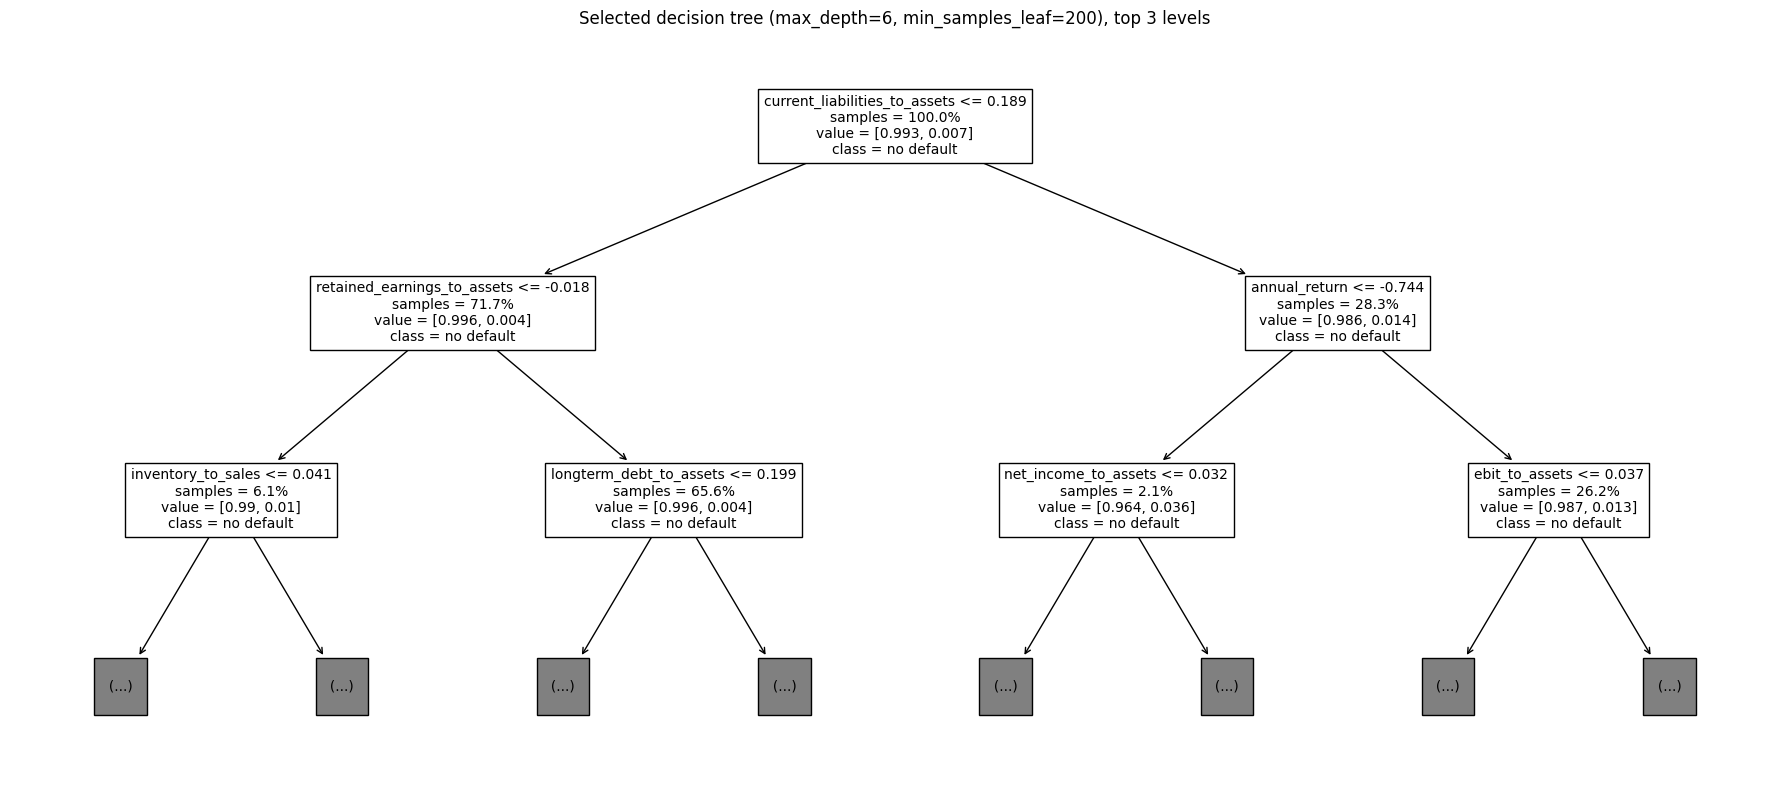

In [26]:
dt_model = dt_fits[dt_best]
tree_feats = [n.split("__")[1] for n in dt_model.named_steps["prep"].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(dt_model.named_steps["clf"], max_depth=2, feature_names=tree_feats, class_names=["no default", "default"],
          filled=False, impurity=False, proportion=True, precision=3, fontsize=10, ax=ax)
ax.set_title(f"Selected decision tree (max_depth={dt_best[0]}, min_samples_leaf={dt_best[1]}), top 3 levels")
plt.tight_layout()
plt.savefig("figures/tree_top_levels.png", dpi=150)
plt.show()

In [27]:
# text version of the same top levels, with default rates in each node
from sklearn.tree import export_text
print(export_text(dt_model.named_steps["clf"], feature_names=tree_feats, max_depth=2, show_weights=True, decimals=3))

|--- current_liabilities_to_assets <= 0.189
|   |--- retained_earnings_to_assets <= -0.018
|   |   |--- inventory_to_sales <= 0.041
|   |   |   |--- truncated branch of depth 4
|   |   |--- inventory_to_sales >  0.041
|   |   |   |--- truncated branch of depth 2
|   |--- retained_earnings_to_assets >  -0.018
|   |   |--- longterm_debt_to_assets <= 0.199
|   |   |   |--- truncated branch of depth 4
|   |   |--- longterm_debt_to_assets >  0.199
|   |   |   |--- truncated branch of depth 4
|--- current_liabilities_to_assets >  0.189
|   |--- annual_return <= -0.744
|   |   |--- net_income_to_assets <= 0.032
|   |   |   |--- truncated branch of depth 2
|   |   |--- net_income_to_assets >  0.032
|   |   |   |--- truncated branch of depth 2
|   |--- annual_return >  -0.744
|   |   |--- ebit_to_assets <= 0.037
|   |   |   |--- truncated branch of depth 4
|   |   |--- ebit_to_assets >  0.037
|   |   |   |--- truncated branch of depth 4



Reading the top of the tree ("value" = [share non-default, share default] in each node):
- **Root split, current_liabilities_to_assets > 0.189:** 28% of firms, default rate 1.4% vs 0.4% for the rest. Firms funded more by short-term liabilities face refinancing pressure every year, so this is a leverage / rollover-risk split.
- **annual_return <= -0.744 (inside the high-liability branch):** firms whose stock lost more than about 74% have a 3.6% default rate, about 5 times the average. The market prices distress before the default happens.
- **retained_earnings_to_assets <= -0.018 (low-liability branch):** firms with an accumulated deficit default at 1.0% vs 0.4%, consistent with young or loss-making firms being riskier.

A deep unconstrained tree overfits because it keeps splitting until each leaf is pure. With only 403 defaults it ends up with 726 leaves that memorize individual defaulters: train AUC goes to 1.0 while validation AUC falls to 0.50 (no better than random). Validation AUC peaks around depth 8 and is flat or falling after that.

### Random Forest (bagging) tuning

In [28]:
rows, rf_fits = [], {}
for d in [6, 10, None]:
    for leaf in [10, 50]:
        for mf in ["sqrt", 0.3]:
            t0 = time.time()
            m = tree_pipe(RandomForestClassifier(n_estimators=300, max_depth=d, min_samples_leaf=leaf, max_features=mf,
                                                 n_jobs=-1, random_state=SEED)).fit(X_train, y_train)
            r = {"max_depth": "None" if d is None else d, "min_samples_leaf": leaf, "max_features": mf,
                 "train_ROC_AUC": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])}
            r.update(rank_metrics(y_valid, m.predict_proba(X_valid)[:, 1]))
            r["sec"] = round(time.time() - t0, 1)
            rows.append(r)
            rf_fits[(d, leaf, mf)] = m
rf_grid = pd.DataFrame(rows)
rf_best = list(rf_fits)[rf_grid.PR_AUC.idxmax()]
print("selected RF (max_depth, min_samples_leaf, max_features):", rf_best, "with n_estimators = 300")
rf_grid.round(4)

selected RF (max_depth, min_samples_leaf, max_features): (6, 50, 0.3) with n_estimators = 300


,max_depth,min_samples_leaf,max_features,train_ROC_AUC,ROC_AUC,PR_AUC,KS,Top10_capture,sec
0,6,10,sqrt,0.8887,0.6721,0.0215,0.2454,0.2644,1.6000
1,6,10,0.3000,0.8941,0.6650,0.0217,0.2354,0.2644,2.6000
2,6,50,sqrt,0.8605,0.6749,0.0217,0.2560,0.2529,1.6000
3,6,50,0.3000,0.8698,0.6700,0.0238,0.2706,0.2644,2.6000
4,10,10,sqrt,0.9921,0.6565,0.0185,0.2508,0.2414,2.3000
5,10,10,0.3000,0.9907,0.6533,0.0161,0.2663,0.1954,4.3000
6,10,50,sqrt,0.9663,0.6595,0.0195,0.2885,0.2414,2.3000
7,10,50,0.3000,0.9695,0.6596,0.0210,0.2497,0.2414,4.2000
8,None,10,sqrt,0.9999,0.6451,0.0150,0.2492,0.1954,3.2000
9,None,10,0.3000,0.9998,0.6180,0.0150,0.1843,0.2184,6.0000


### Boosted trees (GradientBoostingClassifier) tuning
Each (learning_rate, max_depth) pair is fit once with 400 rounds and scored at 100, 200 and 400 rounds with `staged_predict_proba`.

In [29]:
rows, gb_fits = [], {}
stages = [100, 200, 400]
for lr in [0.05, 0.1]:
    for d in [2, 3]:
        t0 = time.time()
        m = tree_pipe(GradientBoostingClassifier(n_estimators=400, learning_rate=lr, max_depth=d, subsample=0.8,
                                                 min_samples_leaf=20, random_state=SEED)).fit(X_train, y_train)
        Xt = m.named_steps["prep"].transform(X_train)
        Xv = m.named_steps["prep"].transform(X_valid)
        tr_stage = list(m.named_steps["clf"].staged_predict_proba(Xt))
        va_stage = list(m.named_steps["clf"].staged_predict_proba(Xv))
        for n in stages:
            r = {"learning_rate": lr, "max_depth": d, "n_estimators": n,
                 "train_ROC_AUC": roc_auc_score(y_train, tr_stage[n - 1][:, 1])}
            r.update(rank_metrics(y_valid, va_stage[n - 1][:, 1]))
            rows.append(r)
        gb_fits[(lr, d)] = m
        print(f"lr={lr}, depth={d}: {time.time() - t0:.0f}s")
gb_grid = pd.DataFrame(rows)
best = gb_grid.loc[gb_grid.PR_AUC.idxmax()]
gb_best = (best.learning_rate, int(best.max_depth), int(best.n_estimators))
print("selected GBM (learning_rate, max_depth, n_estimators):", gb_best)
gb_grid.round(4)

lr=0.05, depth=2: 55s


lr=0.05, depth=3: 82s


lr=0.1, depth=2: 54s


lr=0.1, depth=3: 80s
selected GBM (learning_rate, max_depth, n_estimators): (0.05, 2, 400)


,learning_rate,max_depth,n_estimators,train_ROC_AUC,ROC_AUC,PR_AUC,KS,Top10_capture
0,0.0500,2,100,0.7578,0.6730,0.0276,0.2567,0.2644
1,0.0500,2,200,0.7870,0.6821,0.0273,0.2751,0.2759
2,0.0500,2,400,0.8249,0.6821,0.0325,0.2741,0.2874
3,0.0500,3,100,0.8111,0.6788,0.0263,0.2682,0.2759
4,0.0500,3,200,0.8554,0.6744,0.0305,0.2608,0.2414
5,0.0500,3,400,0.9169,0.6689,0.0283,0.2774,0.2299
6,0.1000,2,100,0.7816,0.6712,0.0222,0.2708,0.2529
7,0.1000,2,200,0.8195,0.6712,0.0289,0.2785,0.2529
8,0.1000,2,400,0.8785,0.6617,0.0302,0.2458,0.2644
9,0.1000,3,100,0.8386,0.6692,0.0184,0.2577,0.2644


In [30]:
# refit the selected boosting setting with exactly the chosen number of rounds
gb_model = tree_pipe(GradientBoostingClassifier(n_estimators=gb_best[2], learning_rate=gb_best[0], max_depth=gb_best[1],
                                                subsample=0.8, min_samples_leaf=20, random_state=SEED)).fit(X_train, y_train)
final_models["M4 Tree"] = dt_model
final_models["M5 RF"] = rf_fits[rf_best]
final_models["M6 GBM"] = gb_model
for k in ["M4 Tree", "M5 RF", "M6 GBM"]:
    val_pred[k] = final_models[k].predict_proba(X_valid)[:, 1]

all_val = pd.DataFrame({k: rank_metrics(y_valid, p) for k, p in val_pred.items()}).T
all_val["train_ROC_AUC"] = [roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in final_models.values()]
all_val.round(4)

,ROC_AUC,PR_AUC,KS,Top10_capture,train_ROC_AUC
M1 Logit,0.6775,0.0220,0.2825,0.2989,0.7063
M2 LASSO,0.6939,0.0265,0.3022,0.3218,0.7055
M3 Ridge,0.6938,0.0267,0.3076,0.2989,0.7070
M4 Tree,0.6106,0.0182,0.2170,0.2529,0.7807
M5 RF,0.6700,0.0238,0.2706,0.2644,0.8698
M6 GBM,0.6821,0.0325,0.2741,0.2874,0.8249


Notes on trees, bagging and boosting:
- **Single tree:** one set of hard splits fit greedily. It is easy to read, but has high variance (a small change in the data changes the splits) and gives only a few distinct probabilities, so its ranking is coarse. It is the weakest model here (validation ROC-AUC 0.61).
- **Bagging / Random Forest:** many deep-ish trees, each grown on a bootstrap sample and with a random subset of features at each split, then averaged. Averaging cuts the variance of a single tree. Here the best forest is the shallowest one in the grid (max_depth 6, leaf 50). Deeper forests reach train AUC near 1.0 but do worse on validation, so with this few defaults the forest still overfits if the trees are allowed to grow.
- **Boosting:** small trees grown one after another, each fitted to the errors of the current model, with a learning rate that shrinks every step. It reduces bias step by step rather than averaging out variance. The slow, shallow setting (learning rate 0.05, depth 2, 400 rounds) is best, and has the highest validation PR-AUC of all six models (0.033). Faster or deeper settings overfit (train AUC up to 0.97 with lower validation).
- The linear models still have the best validation ROC-AUC (0.694 vs 0.682 for boosting). The main relationships look close to monotone (more leverage, worse returns, more risk), which a linear logit captures well. Boosting seems to add value mainly at the very top of the risk ranking, which is where PR-AUC is measured.
- The GBM choice of 400 rounds is the edge of the small grid, so slightly more rounds might help a little, but I kept the grid small as asked.

## 4. Class imbalance experiment (Random Forest)
Same forest settings as the selected M5 (max_depth 6, min_samples_leaf 50, max_features 0.3, 300 trees), trained three ways. Undersampling keeps all 403 training defaults and draws an equal number of non-defaults (1:1), on the training sample only. Validation is never rebalanced.

Precision and recall need a cutoff, so I report them at the fixed 0.5 cutoff and at the cutoff that maximizes F1 on validation.

In [31]:
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    i = np.nanargmax(f1)
    return thr[i]


def threshold_metrics(y, p, t):
    pred = (p >= t).astype(int)
    return {"threshold": t, "flagged": pred.sum(), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred, zero_division=0)}


def undersample(X, y, seed):
    rng = np.random.RandomState(seed)
    pos = np.where(y == 1)[0]
    neg = rng.choice(np.where(y == 0)[0], size=len(pos), replace=False)
    idx = np.sort(np.concatenate([pos, neg]))
    return X.iloc[idx], y[idx]


rf_params = dict(n_estimators=300, max_depth=rf_best[0], min_samples_leaf=rf_best[1], max_features=rf_best[2],
                 n_jobs=-1, random_state=SEED)
X_us, y_us = undersample(X_train, y_train, SEED)
print("undersampled training set:", len(y_us), "rows,", y_us.sum(), "defaults")

imb_models = {
    "Unweighted": tree_pipe(RandomForestClassifier(**rf_params)).fit(X_train, y_train),
    "Class-weighted": tree_pipe(RandomForestClassifier(class_weight="balanced", **rf_params)).fit(X_train, y_train),
    "Undersampled 1:1": tree_pipe(RandomForestClassifier(**rf_params)).fit(X_us, y_us),
}

rows = []
imb_pred = {}
for name, m in imb_models.items():
    p = m.predict_proba(X_valid)[:, 1]
    imb_pred[name] = p
    r = {"treatment": name, "mean_prob": p.mean()}
    r.update(rank_metrics(y_valid, p))
    for tag, t in [("@0.5", 0.5), ("@F1max", best_f1_threshold(y_valid, p))]:
        tm = threshold_metrics(y_valid, p, t)
        for k, v in tm.items():
            r[f"{k}{tag}"] = v
    rows.append(r)
imb_tab = pd.DataFrame(rows).set_index("treatment")
imb_tab.T.round(4)

undersampled training set: 806 rows, 403 defaults


treatment,Unweighted,Class-weighted,Undersampled 1:1
mean_prob,0.0057,0.2834,0.4057
ROC_AUC,0.6700,0.6720,0.6711
PR_AUC,0.0238,0.0195,0.0230
KS,0.2706,0.2790,0.2639
Top10_capture,0.2644,0.2414,0.2759
threshold@0.5,0.5000,0.5000,0.5000
flagged@0.5,0.0000,"1,182.0000","3,147.0000"
precision@0.5,0.0000,0.0203,0.0149
recall@0.5,0.0000,0.2759,0.5402
F1@0.5,0.0000,0.0378,0.0291


In [32]:
# undersampling depends on which non-defaults are drawn, so repeat it with 5 different draws
rows = []
for s in range(5):
    Xs, ys = undersample(X_train, y_train, SEED + s)
    p = tree_pipe(RandomForestClassifier(**rf_params)).fit(Xs, ys).predict_proba(X_valid)[:, 1]
    rows.append(rank_metrics(y_valid, p))
us_rep = pd.DataFrame(rows)
print("undersampling over 5 draws (validation):")
us_rep.agg(["mean", "std", "min", "max"]).round(4)

undersampling over 5 draws (validation):


,ROC_AUC,PR_AUC,KS,Top10_capture
mean,0.6713,0.0232,0.2627,0.2989
std,0.0013,0.0030,0.0055,0.0182
min,0.6692,0.0213,0.2531,0.2759
max,0.6724,0.0284,0.2674,0.3218


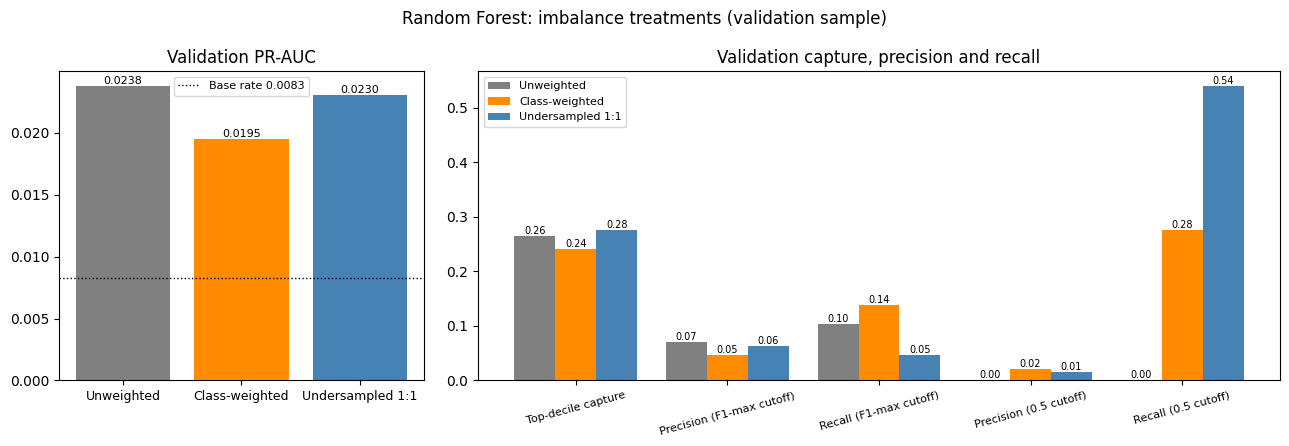

In [33]:
plot_cols = {"PR_AUC": "PR-AUC", "Top10_capture": "Top-decile capture", "precision@F1max": "Precision (F1-max cutoff)",
             "recall@F1max": "Recall (F1-max cutoff)", "precision@0.5": "Precision (0.5 cutoff)", "recall@0.5": "Recall (0.5 cutoff)"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})
colors = ["gray", "darkorange", "steelblue"]
xs = np.arange(len(imb_tab))
axes[0].bar(xs, imb_tab.PR_AUC, color=colors)
axes[0].axhline(y_valid.mean(), color="black", ls=":", lw=1, label=f"Base rate {y_valid.mean():.4f}")
axes[0].set_xticks(xs)
axes[0].set_xticklabels(imb_tab.index, fontsize=9)
axes[0].set_title("Validation PR-AUC")
axes[0].legend(fontsize=8)
for i, v in enumerate(imb_tab.PR_AUC):
    axes[0].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)

cols = list(plot_cols)[1:]
w = 0.27
xx = np.arange(len(cols))
for i, (name, col) in enumerate(zip(imb_tab.index, colors)):
    vals = imb_tab.loc[name, cols].astype(float).values
    axes[1].bar(xx + (i - 1) * w, vals, width=w, color=col, label=name)
    for x, v in zip(xx + (i - 1) * w, vals):
        axes[1].text(x, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
axes[1].set_xticks(xx)
axes[1].set_xticklabels([plot_cols[c] for c in cols], fontsize=8, rotation=15)
axes[1].set_title("Validation capture, precision and recall")
axes[1].legend(fontsize=8)
plt.suptitle("Random Forest: imbalance treatments (validation sample)")
plt.tight_layout()
plt.savefig("figures/imbalance_comparison.png", dpi=200)
plt.show()

In [34]:
# selection rule (validation only, before any test results): highest PR-AUC
imb_choice = imb_tab.PR_AUC.idxmax()
print("selected imbalance treatment:", imb_choice)
print("final M5 stays the", imb_choice.lower(), "forest:", imb_choice == "Unweighted")

selected imbalance treatment: Unweighted
final M5 stays the unweighted forest: True


Imbalance results (validation):
- The three treatments rank firms almost the same way: ROC-AUC 0.670-0.672, and the PR-AUC gap (0.020-0.024) is about the size of the variation between undersampling draws (sd 0.003). Rebalancing mainly **moves the probabilities up** (mean predicted PD 0.006 unweighted vs 0.28 weighted and 0.41 undersampled), not the ordering.
- At the 0.5 cutoff the unweighted forest flags nobody (recall 0), while the undersampled one flags 3,147 firms (30% of the sample) to catch 54% of defaults, at 1.5% precision. That is roughly 66 false alarms per default caught.
- Once the cutoff is chosen on validation (F1-max), the unweighted model has the best precision (7.0%) and F1 (0.084). Class weighting catches a few more defaults (recall 14% vs 10%) by flagging twice as many firms.
- **Choice: unweighted training.** It has the highest PR-AUC and F1, keeps probabilities on the real default-rate scale (needed for pricing and calibration), and uses all the data. Undersampling throws away 98.6% of the non-defaults, and its slightly higher top-decile capture is within draw-to-draw noise. The "more defaults caught" effect of rebalancing can be had more cheaply by lowering the cutoff of the unweighted model.
- Trade-off: a lower cutoff (or rebalancing) catches more defaults but every extra default costs dozens of false positives. Which point is right depends on the cost of a missed default (credit loss) vs the cost of a false alarm (lost business, review time).

## Frozen final specifications (validation only)
All choices below are made on the validation sample. Each model is fit on the training sample only, and the cutoff for precision / recall / F1 is the validation F1-max cutoff, applied unchanged to the test sample.

In [35]:
spec_text = {
    "M1 Logit": "no penalty, 19 ratios + industry",
    "M2 LASSO": f"L1, C={best_C['LASSO']}",
    "M3 Ridge": f"L2, C={best_C['Ridge']}",
    "M4 Tree": f"max_depth={dt_best[0]}, min_samples_leaf={dt_best[1]}",
    "M5 RF": f"300 trees, max_depth={rf_best[0]}, min_samples_leaf={rf_best[1]}, max_features={rf_best[2]}, {imb_choice.lower()}",
    "M6 GBM": f"lr={gb_best[0]}, max_depth={gb_best[1]}, {gb_best[2]} rounds, subsample 0.8",
}
thresholds = {k: best_f1_threshold(y_valid, p) for k, p in val_pred.items()}
frozen = all_val[["ROC_AUC", "PR_AUC", "KS", "Top10_capture"]].copy()
frozen.insert(0, "spec", pd.Series(spec_text))
frozen["val_F1max_threshold"] = pd.Series(thresholds)
frozen["val_F1"] = [threshold_metrics(y_valid, val_pred[k], thresholds[k])["F1"] for k in frozen.index]
print(frozen.round(4).to_string())

# models used later, picked on validation only
best_linear = max(["M1 Logit", "M2 LASSO", "M3 Ridge"], key=lambda k: all_val.loc[k, "PR_AUC"])
best_tree = max(["M4 Tree", "M5 RF", "M6 GBM"], key=lambda k: all_val.loc[k, "PR_AUC"])
best_rank = all_val.PR_AUC.idxmax()
print("\nbest linear (val PR-AUC):", best_linear, "| best tree-based:", best_tree, "| strongest validation ranking (PR-AUC):", best_rank)

                                                                               spec  ROC_AUC  PR_AUC     KS  Top10_capture  val_F1max_threshold  val_F1
M1 Logit                                           no penalty, 19 ratios + industry   0.6775  0.0220 0.2825         0.2989               0.0179  0.0698
M2 LASSO                                                                  L1, C=0.1   0.6939  0.0265 0.3022         0.3218               0.0194  0.0778
M3 Ridge                                                                 L2, C=0.01   0.6938  0.0267 0.3076         0.2989               0.0156  0.0912
M4 Tree                                           max_depth=6, min_samples_leaf=200   0.6106  0.0182 0.2170         0.2529               0.0329  0.0711
M5 RF     300 trees, max_depth=6, min_samples_leaf=50, max_features=0.3, unweighted   0.6700  0.0238 0.2706         0.2644               0.0170  0.0837
M6 GBM                              lr=0.05, max_depth=2, 400 rounds, subsample 0.8   0.

## 5. Final out-of-sample evaluation (test sample, 2015-2018)
This is the only place the test outcomes are used.

In [36]:
test_pred = {k: m.predict_proba(X_test)[:, 1] for k, m in final_models.items()}
rows = []
for k, p in test_pred.items():
    r = rank_metrics(y_test, p)
    tm = threshold_metrics(y_test, p, thresholds[k])
    r.update({"precision": tm["precision"], "recall": tm["recall"], "F1": tm["F1"], "flagged": tm["flagged"],
              "threshold": thresholds[k], "accuracy@thr": accuracy_score(y_test, (p >= thresholds[k]).astype(int)),
              "accuracy@0.5": accuracy_score(y_test, (p >= 0.5).astype(int)), "flagged@0.5": int((p >= 0.5).sum())})
    rows.append(r)
test_tab = pd.DataFrame(rows, index=list(test_pred))
print(f"test sample: {len(y_test)} firm-years, {y_test.sum()} defaults, base rate {y_test.mean():.4f}")
print(f"accuracy of always predicting no default: {1 - y_test.mean():.4f}")
test_tab[["ROC_AUC", "PR_AUC", "KS", "precision", "recall", "F1", "Top10_capture", "threshold", "flagged",
          "accuracy@thr", "accuracy@0.5", "flagged@0.5"]].round(4)

test sample: 12282 firm-years, 119 defaults, base rate 0.0097
accuracy of always predicting no default: 0.9903


,ROC_AUC,PR_AUC,KS,precision,recall,F1,Top10_capture,threshold,flagged,accuracy@thr,accuracy@0.5,flagged@0.5
M1 Logit,0.7206,0.0355,0.3318,0.0475,0.1261,0.0690,0.3277,0.0179,316,0.9670,0.9903,0
M2 LASSO,0.7404,0.0480,0.4037,0.0718,0.1092,0.0867,0.3866,0.0194,181,0.9777,0.9903,0
M3 Ridge,0.7354,0.0491,0.3911,0.0525,0.1765,0.0809,0.3697,0.0156,400,0.9612,0.9903,0
M4 Tree,0.6548,0.0180,0.2976,0.0250,0.0420,0.0313,0.2101,0.0329,200,0.9748,0.9903,0
M5 RF,0.7357,0.0425,0.3665,0.0733,0.1176,0.0903,0.3277,0.0170,191,0.9770,0.9903,0
M6 GBM,0.7068,0.0310,0.3337,0.0537,0.0672,0.0597,0.3109,0.0226,149,0.9795,0.9903,0


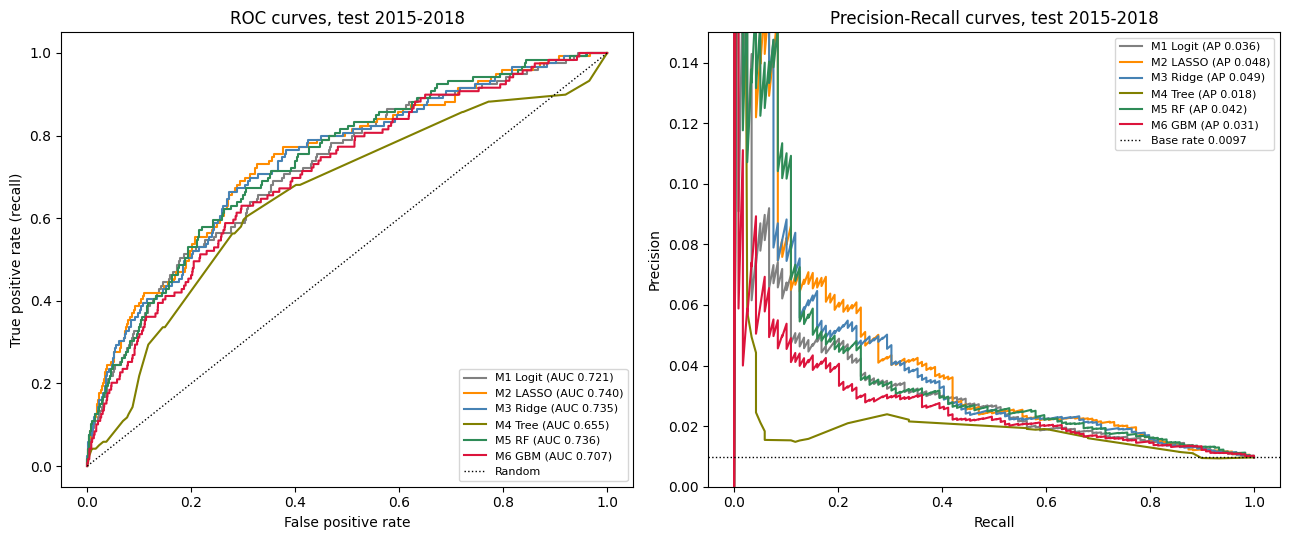

In [37]:
colors6 = dict(zip(final_models, ["gray", "darkorange", "steelblue", "olive", "seagreen", "crimson"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for k, p in test_pred.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors6[k], label=f"{k} (AUC {test_tab.loc[k, 'ROC_AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=colors6[k], label=f"{k} (AP {test_tab.loc[k, 'PR_AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1, label="Random")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves, test 2015-2018")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].axhline(y_test.mean(), color="black", ls=":", lw=1, label=f"Base rate {y_test.mean():.4f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves, test 2015-2018")
axes[1].set_ylim(0, 0.15)
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig("figures/test_roc_pr.png", dpi=200)
plt.show()

### Risk deciles (decile 1 = highest predicted risk)
Deciles are formed from predicted probabilities only. Ties (the single tree has few distinct values) are broken by row order.

In [38]:
def decile_table(y, p):
    d = pd.DataFrame({"y": y, "p": p})
    d["decile"] = pd.qcut(d.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
    t = d.groupby("decile", observed=True).agg(firms=("y", "size"), defaults=("y", "sum"), mean_PD=("p", "mean"))
    t["default_rate"] = t.defaults / t.firms
    t["pct_of_defaults"] = t.defaults / t.defaults.sum()
    t["cum_capture"] = t.pct_of_defaults.cumsum()
    t["lift"] = t.default_rate / d.y.mean()
    return t


dec = {k: decile_table(y_test, p) for k, p in test_pred.items()}
for k in [best_linear, best_tree]:
    print(f"\n{k}: test risk deciles (1 = highest risk)")
    print(dec[k].round(4).to_string())


M3 Ridge: test risk deciles (1 = highest risk)
        firms  defaults  mean_PD  default_rate  pct_of_defaults  cum_capture   lift
decile                                                                             
1        1229        44   0.0149        0.0358           0.3697       0.3697 3.6951
2        1228        16   0.0092        0.0130           0.1345       0.5042 1.3448
3        1228        20   0.0072        0.0163           0.1681       0.6723 1.6809
4        1228        11   0.0060        0.0090           0.0924       0.7647 0.9245
5        1228         5   0.0050        0.0041           0.0420       0.8067 0.4202
6        1228         5   0.0043        0.0041           0.0420       0.8487 0.4202
7        1228         7   0.0036        0.0057           0.0588       0.9076 0.5883
8        1228         5   0.0030        0.0041           0.0420       0.9496 0.4202
9        1228         3   0.0024        0.0024           0.0252       0.9748 0.2521
10       1229         3   0.

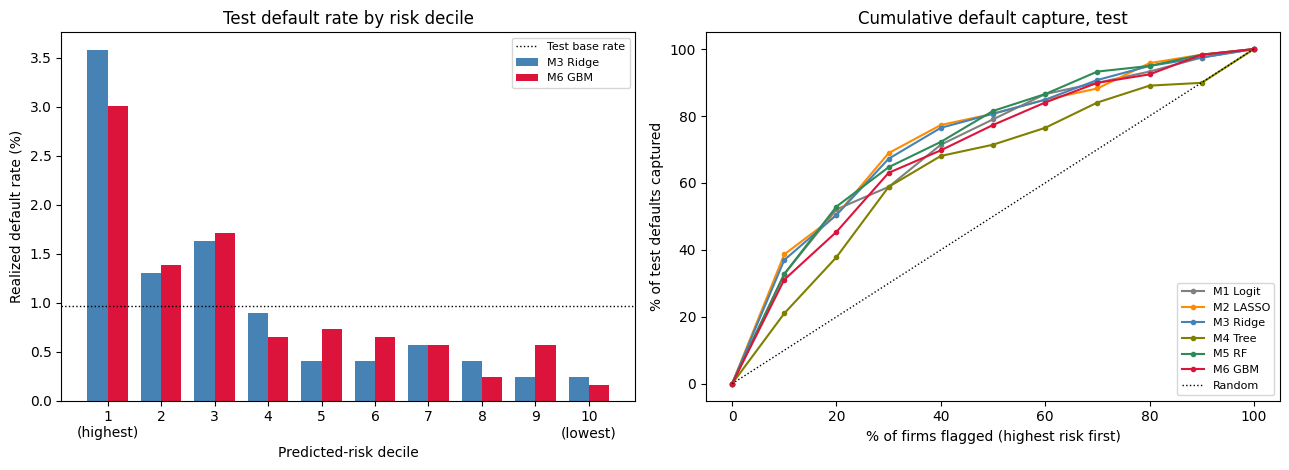

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
w = 0.38
xs = np.arange(1, 11)
for i, k in enumerate([best_linear, best_tree]):
    axes[0].bar(xs + (i - 0.5) * w, 100 * dec[k].default_rate, width=w, color=colors6[k], label=k)
axes[0].axhline(100 * y_test.mean(), color="black", ls=":", lw=1, label="Test base rate")
axes[0].set_xticks(xs)
axes[0].set_xticklabels(["1\n(highest)"] + [str(i) for i in range(2, 10)] + ["10\n(lowest)"])
axes[0].set_xlabel("Predicted-risk decile")
axes[0].set_ylabel("Realized default rate (%)")
axes[0].set_title("Test default rate by risk decile")
axes[0].legend(fontsize=8)

for k in final_models:
    axes[1].plot(np.r_[0, 10 * xs], np.r_[0, 100 * dec[k].cum_capture], marker=".", color=colors6[k], label=k)
axes[1].plot([0, 100], [0, 100], "k:", lw=1, label="Random")
axes[1].set_xlabel("% of firms flagged (highest risk first)")
axes[1].set_ylabel("% of test defaults captured")
axes[1].set_title("Cumulative default capture, test")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("figures/test_deciles_capture.png", dpi=200)
plt.show()

In [40]:
# cumulative capture at the top 10%, 20% and 30% for all models
cap = pd.DataFrame({k: dec[k].cum_capture.loc[[1, 2, 3]].values for k in final_models}, index=["top 10%", "top 20%", "top 30%"]).T
cap.round(3)

,top 10%,top 20%,top 30%
M1 Logit,0.3280,0.5210,0.5880
M2 LASSO,0.3870,0.5040,0.6890
M3 Ridge,0.3700,0.5040,0.6720
M4 Tree,0.2100,0.3780,0.5880
M5 RF,0.3280,0.5290,0.6470
M6 GBM,0.3110,0.4540,0.6300


In [41]:
# test default rate by year, and test ROC-AUC by year for each model
by_year = test.assign(**{k: p for k, p in test_pred.items()}).groupby("target_year")
yr = pd.DataFrame({k: by_year.apply(lambda g: roc_auc_score(g[target], g[k])) for k in final_models})
yr.insert(0, "defaults", by_year[target].sum())
yr.insert(1, "default_rate", by_year[target].mean())
yr.round(3)

,defaults,default_rate,M1 Logit,M2 LASSO,M3 Ridge,M4 Tree,M5 RF,M6 GBM
target_year,,,,,,,,
2016,33,0.0100,0.7260,0.7330,0.7310,0.6780,0.7240,0.7160
2017,29,0.0090,0.7260,0.7570,0.7490,0.6210,0.8130,0.7000
2018,21,0.0070,0.6820,0.6890,0.6900,0.6600,0.6480,0.6850
2019,36,0.0130,0.7240,0.7540,0.7460,0.6500,0.7340,0.7070


Test results (no model choices are changed after this point):
- LASSO has the highest test ROC-AUC (0.740) and KS (0.404) and the best top-decile capture (38.7%). Ridge has the highest PR-AUC (0.049). RF is close on ROC-AUC (0.736) and has the best F1 (0.090) at its validation cutoff.
- GBM had the best validation PR-AUC (0.033) but is only fifth on test (0.031). Validation has just 87 defaults, so PR-AUC differences of a few thousandths are within noise. I keep the validation-based choices anyway, since switching now would be using the test set for selection.
- Test ranking metrics are higher than validation for every model except the single tree (PR-AUC about the same). The test period has more defaults (0.97% vs 0.83%) and the ranking signal seems a bit stronger, not a sign of leakage (all transforms and choices were fixed before this cell).

Why the metrics disagree:
- **Highest ROC-AUC is not highest PR-AUC.** ROC-AUC averages ranking quality over all firms, most of which are safe; PR-AUC only rewards precision among the firms flagged first. LASSO wins ROC-AUC, Ridge wins PR-AUC on test, and on validation the linear models won ROC-AUC while boosting won PR-AUC.
- **Low misclassification can be misleading.** At the 0.5 cutoff every model flags zero firms and has 99.03% accuracy, exactly the same as predicting "no default" for everyone, while catching no defaults at all. At the validation cutoffs accuracy falls to 96-98% even though the models now catch 4-18% of defaults.
- **Ranking is useful even when 0.5 fails.** Predicted PDs are all well below 0.5 (top-decile mean PD is about 1.5%), so the 0.5 rule is useless, yet the top 10% of Ridge scores holds 37% of defaults and a 3.6% default rate (3.7 times the base rate). For credit, the rank is what drives watch lists, limits and pricing.
- **Similar AUC, different deciles.** Ridge (0.735) and RF (0.736) have almost the same AUC, but Ridge puts 44 defaults in decile 1 vs 39 for RF, while RF catches up by decile 2 (53% vs 50% cumulative) and leads at 70% of firms (93% vs 91%). Ridge is better if only a small review list is affordable; RF if the bank screens a wider group. GBM also shows a non-monotone pattern (decile 3 riskier than decile 2, decile 9 riskier than 8).

## 6. Calibration and model interpretation
### Calibration of the strongest validation-ranking model
The calibration maps are fit on the validation predictions only (isotonic regression, and Platt scaling = a logistic regression on the log-odds of the raw score) and then applied to the test predictions.

In [42]:
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression

cal_model = best_rank
p_val_raw, p_test_raw = val_pred[cal_model], test_pred[cal_model]


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_val_raw, y_valid)
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_val_raw), y_valid)
p_test = {"Raw": p_test_raw, "Isotonic": iso.predict(p_test_raw), "Platt": platt.predict_proba(logit(p_test_raw))[:, 1]}

rows = []
for k, p in p_test.items():
    r = {"Brier_x1000": 1000 * brier_score_loss(y_test, p), "mean_PD": p.mean(), "ROC_AUC": roc_auc_score(y_test, p),
         "PR_AUC": average_precision_score(y_test, p), "KS": ks_stat(y_test, p), "Top10_capture": top_decile_capture(y_test, p),
         "distinct_values": len(np.unique(p))}
    rows.append(r)
cal_tab = pd.DataFrame(rows, index=list(p_test))
const = np.full(len(y_test), y_train.mean())
print(f"model: {cal_model} | test default rate {y_test.mean():.4f}")
print(f"reference Brier x1000, constant PD = train default rate: {1000 * brier_score_loss(y_test, const):.4f}")
print(f"reference Brier x1000, constant PD = test default rate (not usable in practice): {1000 * brier_score_loss(y_test, np.full(len(y_test), y_test.mean())):.4f}")
cal_tab

model: M6 GBM | test default rate 0.0097
reference Brier x1000, constant PD = train default rate: 9.6013
reference Brier x1000, constant PD = test default rate (not usable in practice): 9.5951


,Brier_x1000,mean_PD,ROC_AUC,PR_AUC,KS,Top10_capture,distinct_values
Raw,9.5500,0.0057,0.7068,0.0310,0.3337,0.3109,12236
Isotonic,9.5329,0.0091,0.6937,0.0271,0.2908,0.2773,33
Platt,9.5263,0.0089,0.7068,0.0310,0.3337,0.3109,12236


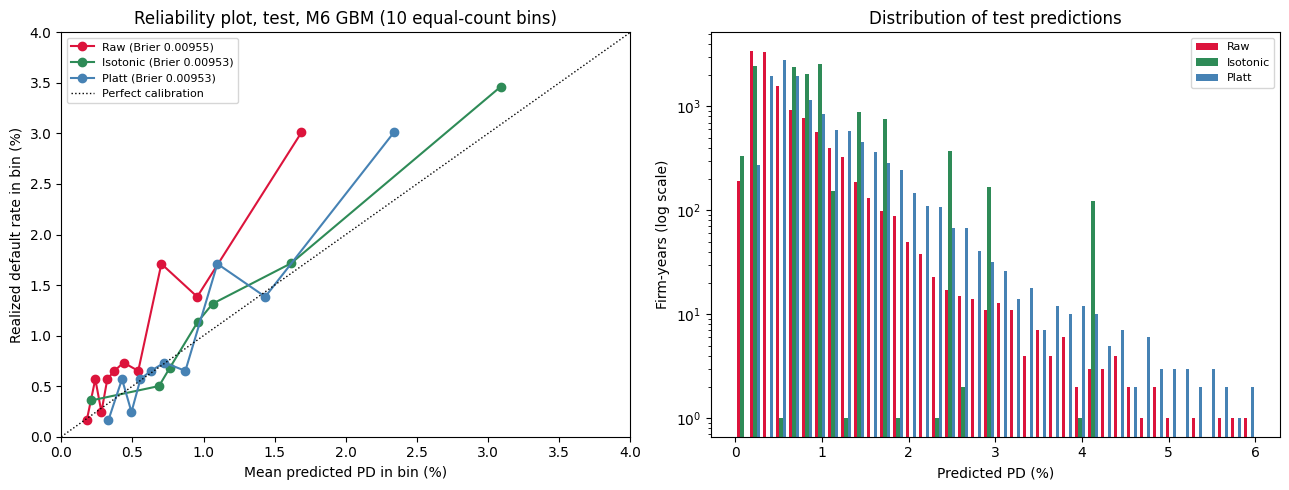

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for k, col in zip(p_test, ["crimson", "seagreen", "steelblue"]):
    frac, mean_p = calibration_curve(y_test, p_test[k], n_bins=10, strategy="quantile")
    axes[0].plot(100 * mean_p, 100 * frac, marker="o", color=col, label=f"{k} (Brier {cal_tab.loc[k, 'Brier_x1000'] / 1000:.5f})")
axes[0].plot([0, 4], [0, 4], "k:", lw=1, label="Perfect calibration")
axes[0].set_xlim(0, 4)
axes[0].set_ylim(0, 4)
axes[0].set_xlabel("Mean predicted PD in bin (%)")
axes[0].set_ylabel("Realized default rate in bin (%)")
axes[0].set_title(f"Reliability plot, test, {cal_model} (10 equal-count bins)")
axes[0].legend(fontsize=8)

axes[1].hist([100 * p for p in p_test.values()], bins=40, range=(0, 6), label=list(p_test), color=["crimson", "seagreen", "steelblue"])
axes[1].set_yscale("log")
axes[1].set_xlabel("Predicted PD (%)")
axes[1].set_ylabel("Firm-years (log scale)")
axes[1].set_title("Distribution of test predictions")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=200)
plt.show()

Calibration notes:
- The raw GBM probabilities are too low: mean PD 0.57% against a realized 0.97%, and every bin in the reliability plot sits above the diagonal. Part of this is the model (boosting with shrinkage pulls scores toward the training base rate of 0.72%) and part is that defaults were more common in 2015-2019 than in the training years.
- Isotonic and Platt maps fit on validation raise the mean PD to about 0.9% and bring the curve much closer to the diagonal, so the probabilities are more usable as PDs.
- The Brier score barely moves (see table). With a 1% default rate the Brier score is dominated by the unavoidable p(1-p) term, so even a constant PD scores about 0.0096; improvements show up in the 4th-5th decimal.
- Platt scaling is a monotone transform, so ROC-AUC, PR-AUC, KS and capture are exactly unchanged. Isotonic regression is piecewise constant (only 33 distinct values on test), which creates ties and lowers test ROC-AUC (0.707 to 0.694) and PR-AUC (0.031 to 0.027). If I deployed this model I would use Platt: same ranking, better-scaled PDs.

In [44]:
# for comparison, calibration of all raw models on test (Brier and mean PD vs realized 0.0097)
pd.DataFrame({"Brier_x1000": {k: 1000 * brier_score_loss(y_test, p) for k, p in test_pred.items()},
              "mean_PD": {k: p.mean() for k, p in test_pred.items()}})

,Brier_x1000,mean_PD
M1 Logit,9.5434,0.0056
M2 LASSO,9.5327,0.0058
M3 Ridge,9.5384,0.0057
M4 Tree,9.5868,0.0059
M5 RF,9.5451,0.0059
M6 GBM,9.5500,0.0057


### Extra: calibration of M2 LASSO
"Strongest validation ranking" can also be read as validation ROC-AUC, where M2 LASSO is first (0.6939, essentially tied with Ridge). I repeat the same calibration for LASSO, again fit on validation predictions only.

In [45]:
def calibrate_and_score(name):
    pv, pt = val_pred[name], test_pred[name]
    iso_m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(pv, y_valid)
    platt_m = LogisticRegression(C=1e6, max_iter=1000).fit(logit(pv), y_valid)
    probs = {"Raw": pt, "Isotonic": iso_m.predict(pt), "Platt": platt_m.predict_proba(logit(pt))[:, 1]}
    tab = pd.DataFrame({k: {"Brier_x1000": 1000 * brier_score_loss(y_test, p), "mean_PD": p.mean(),
                            "ROC_AUC": roc_auc_score(y_test, p), "PR_AUC": average_precision_score(y_test, p),
                            "KS": ks_stat(y_test, p), "Top10_capture": top_decile_capture(y_test, p),
                            "distinct_values": len(np.unique(p))} for k, p in probs.items()}).T
    tab["distinct_values"] = tab["distinct_values"].astype(int)
    return probs, tab


lasso_probs, lasso_cal_tab = calibrate_and_score("M2 LASSO")
print(f"M2 LASSO, test default rate {y_test.mean():.4f}")
lasso_cal_tab

M2 LASSO, test default rate 0.0097


,Brier_x1000,mean_PD,ROC_AUC,PR_AUC,KS,Top10_capture,distinct_values
Raw,9.5327,0.0058,0.7404,0.0480,0.4037,0.3866,12282
Isotonic,9.4483,0.0096,0.7408,0.0389,0.3925,0.3866,33
Platt,9.4733,0.0094,0.7404,0.0480,0.4037,0.3866,12282


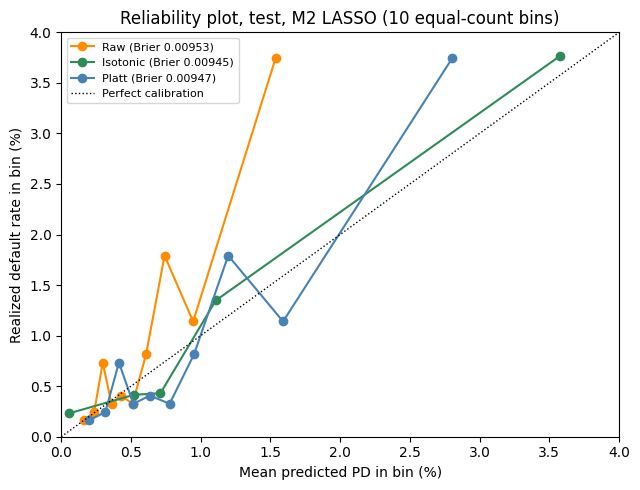

In [46]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for k, col in zip(lasso_probs, ["darkorange", "seagreen", "steelblue"]):
    frac, mean_p = calibration_curve(y_test, lasso_probs[k], n_bins=10, strategy="quantile")
    ax.plot(100 * mean_p, 100 * frac, marker="o", color=col, label=f"{k} (Brier {lasso_cal_tab.loc[k, 'Brier_x1000'] / 1000:.5f})")
ax.plot([0, 4], [0, 4], "k:", lw=1, label="Perfect calibration")
ax.set_xlim(0, 4)
ax.set_ylim(0, 4)
ax.set_xlabel("Mean predicted PD in bin (%)")
ax.set_ylabel("Realized default rate in bin (%)")
ax.set_title("Reliability plot, test, M2 LASSO (10 equal-count bins)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/calibration_lasso.png", dpi=200)
plt.show()

LASSO calibration notes:
- Same picture as GBM: raw PDs are too low (mean 0.58% vs realized 0.97%) and the riskiest bin defaults at 3.7% against a predicted 1.5%. Calibration on validation lifts the mean PD to about 0.95%.
- The Brier gain is larger than for GBM (9.533 to 9.448 isotonic and 9.473 Platt, x1e-3) and both calibrated LASSO versions beat every GBM version.
- Platt again leaves ROC-AUC, PR-AUC, KS and capture exactly unchanged. Isotonic keeps ROC-AUC (0.740 to 0.741) but its ties lower PR-AUC (0.048 to 0.039).
- This supports the recommendation: LASSO + Platt keeps the best ranking and gives the best-scaled PDs of the models I calibrated.

### Interpretation: linear coefficients vs tree-ensemble importance
Ridge (best linear model on validation) is read through its standardized coefficients. For the tree side I use the Random Forest, with permutation importance on the validation sample: each raw column (including industry_code as a whole) is shuffled 10 times and the drop in ROC-AUC is recorded. Native impurity importance is shown as an extra.

In [47]:
from sklearn.inspection import permutation_importance

rf_model = final_models["M5 RF"]
perm = permutation_importance(rf_model, X_valid, y_valid, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
perm_tab = pd.DataFrame({"mean_drop_AUC": perm.importances_mean, "sd": perm.importances_std}, index=X_valid.columns)
perm_tab = perm_tab.sort_values("mean_drop_AUC", ascending=False)

native = pd.Series(rf_model.named_steps["clf"].feature_importances_, index=tree_feats)
native = native.groupby(lambda n: "industry_code" if n.startswith("industry_code") else n).sum().sort_values(ascending=False)

ridge_coef = coefs["M3 Ridge"].loc[cont_linear].sort_values(key=np.abs, ascending=False)
summary = pd.DataFrame({"ridge_coef": ridge_coef, "ridge_rank": np.arange(1, len(ridge_coef) + 1)}).join(
    perm_tab.assign(perm_rank=np.arange(1, len(perm_tab) + 1)), how="outer").join(
    native.rename("native_imp").to_frame().assign(native_rank=lambda d: d.native_imp.rank(ascending=False).astype(int)), how="outer")
summary.sort_values("perm_rank").round(4)

,ridge_coef,ridge_rank,mean_drop_AUC,sd,perm_rank,native_imp,native_rank
longterm_debt_to_assets,0.1776,2.0000,0.0307,0.0138,1,0.0646,6
debt_to_assets,0.1735,3.0000,0.0239,0.0155,2,0.0687,5
equity_to_assets,NaN,NaN,0.0214,0.0153,3,0.0732,3
current_liabilities_to_assets,0.1275,5.0000,0.0195,0.0124,4,0.0922,1
retained_earnings_to_assets,-0.1338,4.0000,0.0101,0.0082,5,0.0608,7
annual_return,-0.1868,1.0000,0.0074,0.0015,6,0.0713,4
ebitda_to_assets,-0.0371,13.0000,0.0049,0.0034,7,0.0385,11
quick_ratio,-0.0532,9.0000,0.0036,0.0023,8,0.0261,21
log_market_value,-0.0744,7.0000,0.0027,0.0016,9,0.0336,14
inventory_to_sales,0.0424,11.0000,0.0026,0.0015,10,0.0343,13


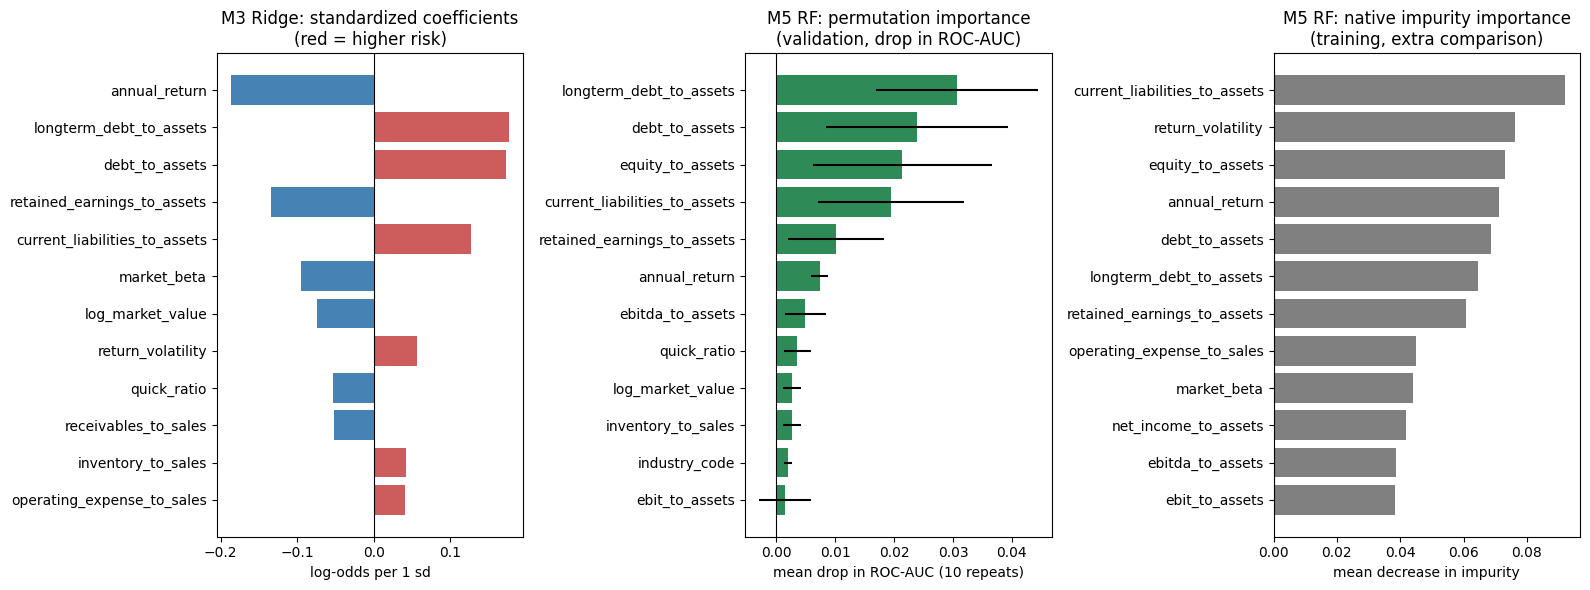

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
top_r = ridge_coef.head(12)[::-1]
axes[0].barh(top_r.index, top_r.values, color=np.where(top_r.values > 0, "indianred", "steelblue"))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("M3 Ridge: standardized coefficients\n(red = higher risk)")
axes[0].set_xlabel("log-odds per 1 sd")

top_p = perm_tab.head(12)[::-1]
axes[1].barh(top_p.index, top_p.mean_drop_AUC, xerr=top_p.sd, color="seagreen")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("M5 RF: permutation importance\n(validation, drop in ROC-AUC)")
axes[1].set_xlabel("mean drop in ROC-AUC (10 repeats)")

top_n = native.head(12)[::-1]
axes[2].barh(top_n.index, top_n.values, color="gray")
axes[2].set_title("M5 RF: native impurity importance\n(training, extra comparison)")
axes[2].set_xlabel("mean decrease in impurity")
plt.tight_layout()
plt.savefig("figures/importance.png", dpi=200)
plt.show()

Interpretation notes:
- Both models agree on the core drivers: **leverage** (long-term debt, total debt, current liabilities), **retained earnings** and **annual return**. Five of these are in the top six of both the Ridge coefficients and the RF permutation importance (Ridge's sixth is market_beta, the forest's is equity_to_assets), which is economically sensible: high debt, a history of losses and a falling stock price are the classic distress signs.
- The order differs. Ridge puts annual_return first, while the forest leans on the leverage block (it uses equity_to_assets as well, which the linear models dropped as an exact duplicate). The forest also gives little permutation importance to volatility, beta and size, which still carry small linear coefficients.
- The permutation error bars are wide because validation only has 87 defaults, and correlated variables share importance: shuffling debt_to_assets alone understates the leverage block because equity_to_assets still carries the same information.
- Native impurity importance ranks return_volatility second, but its permutation importance is close to zero. Impurity importance is measured on the training data and favours continuous variables with many possible split points, so I rely on the permutation ranking.
- Profitability flow ratios (net income, EBIT, EBITDA) matter less than retained earnings in both models. One year's profit is noisy, while retained earnings sums many years of results.

## 7. Stress-period analysis
Economic diagnostic only: all models are already frozen and nothing here feeds back into model choice. Periods are defined on target_year: dot-com 2001-2003, GFC 2007-2009, and all other years as non-stress. Predictors are from the fiscal year before (the year leading into the stress).

In [49]:
def regime(y):
    if 2001 <= y <= 2003:
        return "Dot-com (2001-03)"
    if 2007 <= y <= 2009:
        return "GFC (2007-09)"
    return "Non-stress"


df["regime"] = df.target_year.apply(regime)
reg_order = ["Non-stress", "Dot-com (2001-03)", "GFC (2007-09)"]
reg_tab = df.groupby("regime").agg(years=("target_year", "nunique"), obs=(target, "size"), defaults=(target, "sum"),
                                   default_rate=(target, "mean")).loc[reg_order]
reg_tab["default_rate_%"] = 100 * reg_tab.pop("default_rate")
# non-stress years inside the training period only, as a cleaner comparison
ns_train = df[(df.regime == "Non-stress") & (df.fiscal_year <= 2011)]
print(f"non-stress years inside the training period: default rate {100 * ns_train[target].mean():.3f}% ({ns_train[target].sum()} defaults)")
reg_tab.round(3)

non-stress years inside the training period: default rate 0.689% (201 defaults)


,years,obs,defaults,default_rate_%
regime,,,,
Non-stress,14,51914,407,0.7840
Dot-com (2001-03),3,14774,34,0.2300
GFC (2007-09),3,11994,168,1.4010


In [50]:
stress_vars = ["debt_to_assets", "longterm_debt_to_assets", "current_ratio", "net_income_to_assets", "ebitda_to_assets",
               "retained_earnings_to_assets", "sales_to_assets", "annual_return", "return_volatility", "log_market_value",
               "market_to_book", "market_beta"]
var_type = {v: ("Market" if v in groups["Market"] else "Accounting") for v in stress_vars}
means = df.groupby("regime")[stress_vars].mean().loc[reg_order].T
medians = df.groupby("regime")[stress_vars].median().loc[reg_order].T
print("means:")
print(means.round(3).to_string())
print("\nmedians:")
print(medians.round(3).to_string())

means:
regime                       Non-stress  Dot-com (2001-03)  GFC (2007-09)
debt_to_assets                   0.4000             0.4170         0.4170
longterm_debt_to_assets          0.1960             0.2040         0.2040
current_ratio                    0.9600             0.9100         0.8970
net_income_to_assets             0.0770             0.0630         0.0580
ebitda_to_assets                 0.1440             0.1280         0.1230
retained_earnings_to_assets      0.1610             0.1310         0.1250
sales_to_assets                  1.0090             1.0000         1.0090
annual_return                    0.0550            -0.2730        -0.2010
return_volatility                0.2560             0.2970         0.3240
log_market_value                 9.4980             9.1300         9.2270
market_to_book                   1.7970             1.6010         1.5350
market_beta                      0.9820             0.9870         0.9860

medians:
regime               

In [51]:
# standardized mean difference vs non-stress: (mean_stress - mean_nonstress) / pooled sd
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


base = df[df.regime == "Non-stress"]
smd_tab = pd.DataFrame({r: {v: smd(df.loc[df.regime == r, v], base[v]) for v in stress_vars} for r in reg_order[1:]})
smd_tab.insert(0, "type", pd.Series(var_type))
smd_tab = smd_tab.reindex(smd_tab[reg_order[1:]].abs().max(axis=1).sort_values(ascending=False).index)
smd_tab.round(3)

,type,Dot-com (2001-03),GFC (2007-09)
annual_return,Market,-1.2400,-0.7500
return_volatility,Market,0.4700,0.6440
market_to_book,Market,-0.2900,-0.3680
net_income_to_assets,Accounting,-0.2450,-0.3160
ebitda_to_assets,Accounting,-0.2410,-0.3070
log_market_value,Market,-0.2970,-0.2160
retained_earnings_to_assets,Accounting,-0.2170,-0.2560
current_ratio,Accounting,-0.1330,-0.1650
debt_to_assets,Accounting,0.0900,0.0900
longterm_debt_to_assets,Accounting,0.0830,0.0870


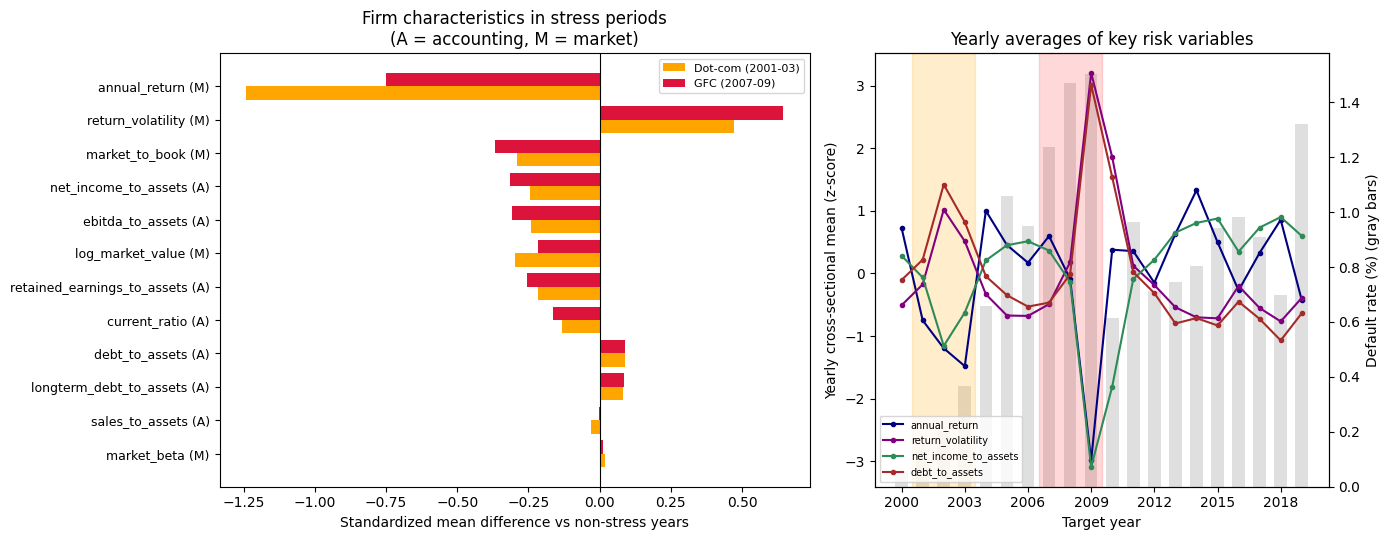

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
order = smd_tab.index[::-1]
yy = np.arange(len(order))
axes[0].barh(yy - 0.2, smd_tab.loc[order, "Dot-com (2001-03)"], height=0.4, color="orange", label="Dot-com (2001-03)")
axes[0].barh(yy + 0.2, smd_tab.loc[order, "GFC (2007-09)"], height=0.4, color="crimson", label="GFC (2007-09)")
axes[0].set_yticks(yy)
axes[0].set_yticklabels([f"{v} ({var_type[v][0]})" for v in order], fontsize=9)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlabel("Standardized mean difference vs non-stress years")
axes[0].set_title("Firm characteristics in stress periods\n(A = accounting, M = market)")
axes[0].legend(fontsize=8)

yearly = df.groupby("target_year")[["annual_return", "return_volatility", "net_income_to_assets", "debt_to_assets"]].mean()
z = (yearly - yearly.mean()) / yearly.std()
for c, col in zip(z.columns, ["navy", "purple", "seagreen", "brown"]):
    axes[1].plot(z.index, z[c], marker=".", color=col, label=c)
axes[1].axvspan(2000.5, 2003.5, color="orange", alpha=0.2)
axes[1].axvspan(2006.5, 2009.5, color="red", alpha=0.15)
ax2 = axes[1].twinx()
ax2.bar(ann.index, 100 * ann.rate, color="gray", alpha=0.25, width=0.6)
ax2.set_ylabel("Default rate (%) (gray bars)")
axes[1].set_zorder(ax2.get_zorder() + 1)
axes[1].patch.set_visible(False)
axes[1].set_xticks(range(2000, 2020, 3))
axes[1].set_xlabel("Target year")
axes[1].set_ylabel("Yearly cross-sectional mean (z-score)")
axes[1].set_title("Yearly averages of key risk variables")
axes[1].legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.savefig("figures/stress_comparison.png", dpi=200)
plt.show()

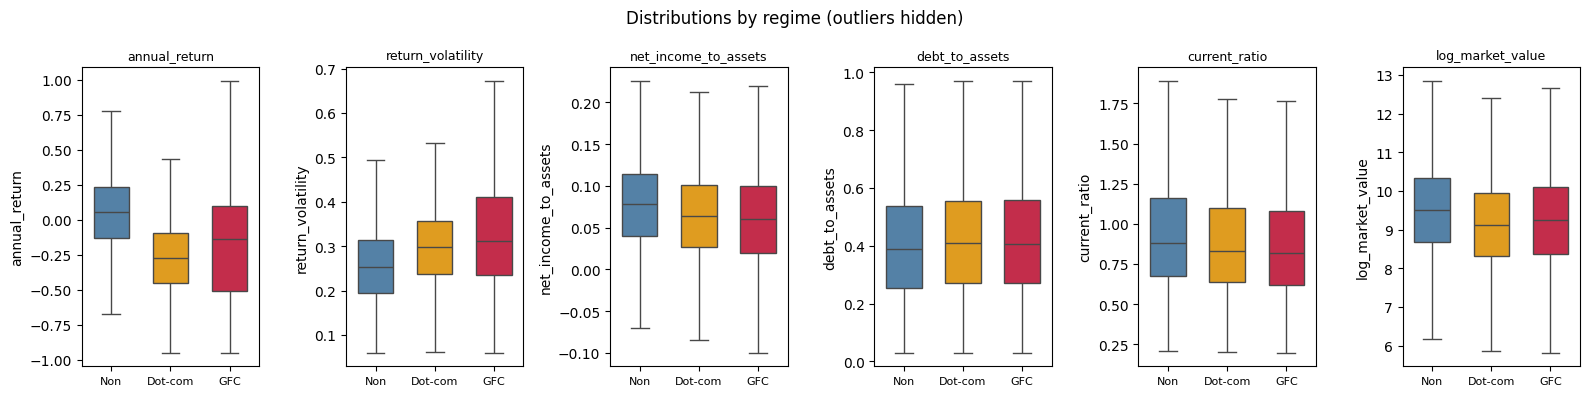

In [53]:
box_vars = ["annual_return", "return_volatility", "net_income_to_assets", "debt_to_assets", "current_ratio", "log_market_value"]
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for ax, v in zip(axes, box_vars):
    sns.boxplot(data=df, x="regime", y=v, order=reg_order, ax=ax, showfliers=False, palette=["steelblue", "orange", "crimson"], width=0.6)
    ax.set_xticklabels(["Non", "Dot-com", "GFC"], fontsize=8)
    ax.set_xlabel("")
    ax.set_title(v, fontsize=9)
plt.suptitle("Distributions by regime (outliers hidden)")
plt.tight_layout()
plt.show()

In [54]:
# do accounting and market variables separate defaulters differently in stress? single-variable AUC by regime,
# oriented so that 0.5 = no information and >0.5 means the variable ranks defaulters as riskier
sign = {v: (-1 if v in ["current_ratio", "net_income_to_assets", "ebitda_to_assets", "retained_earnings_to_assets",
                        "annual_return", "log_market_value", "market_to_book", "sales_to_assets", "market_beta"] else 1)
        for v in stress_vars}
rows = {}
for r in reg_order + ["All stress"]:
    sub = df[df.regime != "Non-stress"] if r == "All stress" else df[df.regime == r]
    rows[r] = {v: roc_auc_score(sub[target], sign[v] * sub[v]) for v in stress_vars}
uni_auc = pd.DataFrame(rows)
uni_auc.insert(0, "type", pd.Series(var_type))
uni_auc["stress_minus_non"] = uni_auc["All stress"] - uni_auc["Non-stress"]
print("defaults per regime:", df.groupby("regime")[target].sum().to_dict())
uni_auc.sort_values("Non-stress", ascending=False).round(3)

defaults per regime: {'Dot-com (2001-03)': 34, 'GFC (2007-09)': 168, 'Non-stress': 407}


,type,Non-stress,Dot-com (2001-03),GFC (2007-09),All stress,stress_minus_non
debt_to_assets,Accounting,0.6740,0.7040,0.6930,0.6940,0.0200
longterm_debt_to_assets,Accounting,0.6680,0.7180,0.6850,0.6900,0.0210
annual_return,Market,0.6390,0.7040,0.6010,0.5890,-0.0510
retained_earnings_to_assets,Accounting,0.6190,0.6210,0.6350,0.6380,0.0190
log_market_value,Market,0.6060,0.5140,0.5880,0.5670,-0.0400
return_volatility,Market,0.5890,0.5900,0.5700,0.5970,0.0080
net_income_to_assets,Accounting,0.5820,0.5820,0.5870,0.5950,0.0130
ebitda_to_assets,Accounting,0.5780,0.5790,0.5720,0.5810,0.0030
current_ratio,Accounting,0.5650,0.4410,0.5880,0.5690,0.0040
market_to_book,Market,0.5550,0.5170,0.5120,0.5280,-0.0270


In [55]:
uni_auc.groupby("type")[reg_order + ["All stress"]].mean().round(3)

,Non-stress,Dot-com (2001-03),GFC (2007-09),All stress
type,,,,
Accounting,0.5970,0.5980,0.6070,0.6090
Market,0.5740,0.5500,0.5550,0.5540


Stress-period notes:
- **Default rates:** the GFC years have 1.40% vs 0.78% in non-stress years. The dot-com window is actually *lower* (0.23%, only 34 defaults); in this sample defaults rise after it, to about 1% in 2005-06. Market stress shows up in the predictors in 2001-03 but the defaults come one to two years later.
- **What moves most:** market variables. Annual return drops by 1.24 sd (dot-com) and 0.75 sd (GFC), volatility rises by 0.47 and 0.64 sd, and M/B and size fall by 0.2-0.4 sd. Accounting profitability and retained earnings fall by 0.2-0.3 sd, liquidity by about 0.15 sd, and leverage barely moves (+0.09 sd).
- **Link to the models:** leverage and retained earnings are the most important predictors but move least in a crisis; they explain *which* firms default. Annual return is important too (first in Ridge) and moves the most; volatility moves a lot but adds little in the forest. So the variables that drive the *timing* of default waves are not the same as the ones that rank firms within a year.
- **Accounting vs market information:** accounting variables separate defaulters about equally well in and out of stress (average single-variable AUC 0.60-0.61), while market variables lose power in stress (0.574 non-stress to 0.555 stress). When the whole market falls, a bad return says less about a single firm. Pooling both stress periods even lowers the AUC of annual_return to 0.59, because a -27% average return meant few defaults in 2001-03 but many in 2007-09.
- **Why relationships are not stable:** the base default rate, the level of returns and volatility, and the link between a given return and default all change between regimes (the dot-com stress came with few defaults, the GFC with many). A model fit mostly on calm years learns a mapping from ratios to PD that is too low in a crisis, which is what we already saw in calibration (raw PDs too low in 2015-19).
- **Deployment:** monitor the model by year (ranking AUC and realized vs predicted default rate), re-calibrate the PD level on recent data more often than the ranking model is re-estimated, stress-test the portfolio with crisis-period inputs, and do not rely on market variables alone when markets fall across the board.

## Recommendation for a credit-risk team
- **Model:** M2 LASSO logit with Platt calibration fit on the latest data. It had the best validation ROC-AUC (tied with Ridge) and the best validation top-decile capture, uses only 11 inputs with signs that make economic sense (leverage +, retained earnings -, returns -, volatility +, size -), and on test it ranked first on ROC-AUC, KS and top-decile capture. RF is a good challenger model to run in parallel.
- **Not the highest AUC automatically:** AUC differences between LASSO, Ridge and RF are within a few thousandths, and validation has only 87 defaults, so these gaps are noise. GBM had the best validation PR-AUC but was miscalibrated, hard to explain, and dropped on test. With similar ranking, the simpler, stable and explainable model wins.
- **How each criterion enters:** ranking (top-decile capture) decides who goes on the watch list; calibration matters for pricing, provisions and capital, so the PD level is re-fit separately; interpretability is needed for credit committees and model validation; stability across regimes favours a few strong, monotone drivers; and the cutoff should come from the cost of a missed default vs a false alarm, not from 0.5 or a pure F1 rule.
- **Limitations:** anonymized teaching data (not real CRSP/Compustat), few defaults (87 in validation, 119 in test) so metrics are noisy, one-year horizon only, no macro variables, a single chronological split rather than rolling windows, firms that drop out of the sample without a recorded default, and stress periods that sit only in the training sample, so we never see an out-of-sample crisis.